# Fit FELTOR magnetic field coefficients to VMEC equilibrium

This notebook explains how to convert a VMEC magnetic field equilibrium to an input file for FELTOR. 
It is recommended to read up on how FELTOR sets up the magnetic field in the documentation "feltor/src/feltor/feltor.tex" (compile to pdf using make doc).

Other useful resources are
https://arxiv.org/pdf/2502.04374

and
https://github.com/proximafusion/vmecpp/blob/main/examples/visualize_magnetic_field.py

## 1. Reading and exploring VMEC

First, we need to read and understand the experimental magnetic field data. What we are looking for is the poloidal flux function $\psi_p(R,Z,\varphi)$ and the poloidal angle $\theta_F := q\theta + q \lambda$, where $\theta$ is the VMEC poloidal angle and $\lambda$ is a VMEC function and $q$ is the q-profile.

The magnetic field is then given by
\begin{align}
\vec B = \nabla \psi_p \times \nabla \theta_F + \nabla \psi_p \times \nabla \varphi
\end{align}

In a first step let us try to plot $\psi_p$, $\theta$ and $\lambda$ in a 2d plane

In [1]:
import numpy as np
from simsopt.mhd import Vmec
from pyfeltor import dg

import matplotlib.pyplot as plt

In [2]:
vmec = Vmec( "wout_nice.nc")
# vmec = Vmec( "wout_w7x.nc")
wout = vmec.wout

## Polynomial Fit of $\psi_p(s)$

We begin by inspecting the $\psi_t(s)$ and $\psi_p(s)$ functions and fitting a polynomial.

In [3]:
# This is the "full grid" in s that VMEC uses
num_s = wout.ns
grid_s = np.linspace(0.0, 1.0, num_s, endpoint=True) # == vmec.s_full_grid

In [4]:
fit1d_coeffs = np.polyfit( grid_s[1:], wout.chi[1:],5)
chi_fit = -np.poly1d(fit1d_coeffs)(grid_s)
chipf_fit = np.poly1d(np.polyder( -fit1d_coeffs))(grid_s) # !! There is a zero in the derivative
print ( "Fitting error derivative ", np.linalg.norm( chipf_fit - wout.chipf, 2))
print ( "Fitting error original   ", np.linalg.norm( chi_fit + wout.chi, 2))

# Reverse order (guarantees that psi_p(0) = 0
fit1d_coeffs = np.polyfit( grid_s[1:], wout.chipf[1:],4)
chipf_fit = np.poly1d(fit1d_coeffs)(grid_s)
chi_fit = np.poly1d(np.polyint( fit1d_coeffs))(grid_s)
print ( "Fitting error derivative ", np.linalg.norm( chipf_fit - wout.chipf, 2))
print ( "Fitting error original   ", np.linalg.norm( chi_fit + wout.chi, 2))

Fitting error derivative  3.4440015155549066e-05
Fitting error original    1.3438305045771766e-06
Fitting error derivative  2.2419878594902913e-05
Fitting error original    3.730909512950271e-06


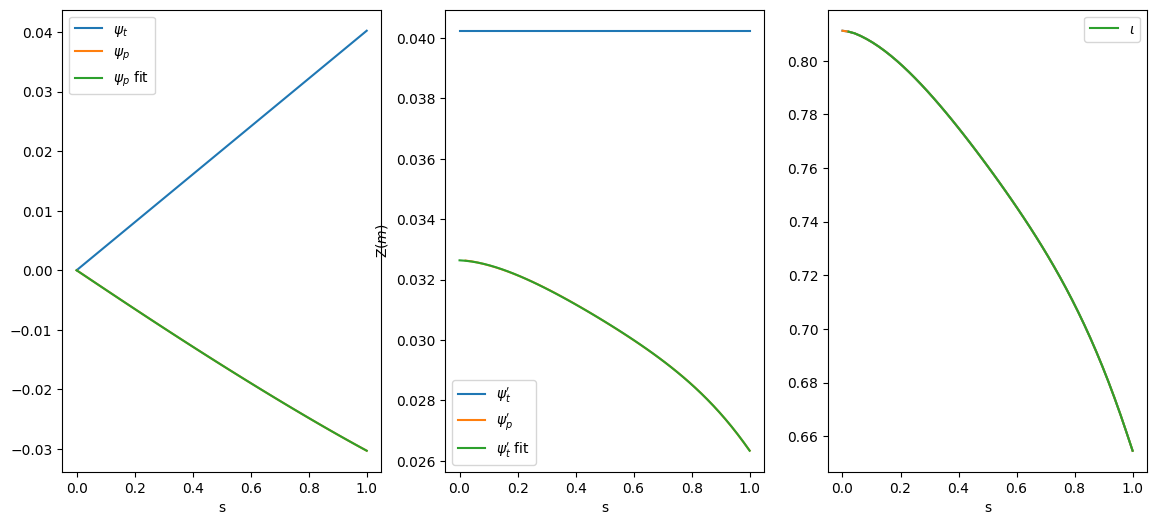

In [5]:
fig, axes = plt.subplots(nrows=1, ncols=3, sharex=True, figsize=(14, 6), squeeze=False)

ax = axes[0][0]
# cf = ax.contour(r, z, psip, 15)
# ax.clabel(cf)
ax.plot( grid_s,wout.phi, label=r"$\psi_t$")
ax.plot( grid_s,wout.chi, label=r"$\psi_p$")
ax.plot( grid_s,-chi_fit, label=r"$\psi_p$ fit")
ax.set_xlabel(r"s")
# ax.set_ylabel(r"$\phi$")
ax.legend()
ax = axes[0][1]
ax.plot( grid_s, wout.phipf, label=r"$\psi_t'$")
ax.plot( grid_s[1:], wout.chipf[1:], label=r"$\psi_p'$")
ax.plot( grid_s, chipf_fit, label=r"$\psi_t'$ fit")
ax.set_xlabel(r"s")
ax.set_ylabel(r"Z($m$)")
ax.legend()
ax = axes[0][2]
ax.plot( grid_s, wout.iotaf)
ax.plot( grid_s, 1./wout.q_factor)
ax.plot( grid_s[1:], wout.chipf[1:]/wout.phipf[1:], label=r"$\iota$")
ax.set_xlabel(r"s")
ax.legend()
# fig.colorbar(cf, ax=ax)
# ax.set_title(r"$\lambda$")
# fig.tight_layout()

plt.show()

Note how the derivative $\psi_p'$ has a different sign than $\partial \psi_p  / \partial s$

## Read and display 3d data

In [6]:
# We create a theta-phi grid on which to evaluate the 3d fields
num_theta = 128
num_phi = 64

# Grid in theta and phi 
grid_theta = np.linspace(0.0, 2 * np.pi, num_theta, endpoint=False)
grid_phi = np.linspace( 0.0, 2*np.pi / wout.nfp, num_phi, endpoint = False)

# We remove the s=0 line  (else the least squares tends to become singular)
num_sz = num_s -1
grid_sz = grid_s[1:]
grid_half_sz = grid_sz - vmec.ds/2

# Choose a phi value
phi_idx = 4
phi = grid_phi[phi_idx]

In [7]:
# mnmax = wout.mnmax
# Poloidal and toroidal mode numbers [0:mnmax]
xm = wout.xm
xn = wout.xn

# To illustrate show the m_k and n_k modes
print( "Number of modes ", len(xm))
print( xm, xn)

print(wout.mpol,wout.ntor)


Number of modes  98
[0. 0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 2. 2. 2. 2.
 2. 2. 2. 2. 2. 2. 2. 2. 2. 3. 3. 3. 3. 3. 3. 3. 3. 3. 3. 3. 3. 3. 4. 4.
 4. 4. 4. 4. 4. 4. 4. 4. 4. 4. 4. 5. 5. 5. 5. 5. 5. 5. 5. 5. 5. 5. 5. 5.
 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 7. 7. 7. 7. 7. 7. 7. 7. 7. 7. 7.
 7. 7.] [  0.   5.  10.  15.  20.  25.  30. -30. -25. -20. -15. -10.  -5.   0.
   5.  10.  15.  20.  25.  30. -30. -25. -20. -15. -10.  -5.   0.   5.
  10.  15.  20.  25.  30. -30. -25. -20. -15. -10.  -5.   0.   5.  10.
  15.  20.  25.  30. -30. -25. -20. -15. -10.  -5.   0.   5.  10.  15.
  20.  25.  30. -30. -25. -20. -15. -10.  -5.   0.   5.  10.  15.  20.
  25.  30. -30. -25. -20. -15. -10.  -5.   0.   5.  10.  15.  20.  25.
  30. -30. -25. -20. -15. -10.  -5.   0.   5.  10.  15.  20.  25.  30.]
8 6


In [8]:
R = np.zeros( (num_s,num_theta,num_phi))
Z = np.zeros( (num_s,num_theta,num_phi))
s, t, p = np.meshgrid( grid_s, grid_theta, grid_phi,indexing='ij')
lambda_half = np.zeros( (num_s, num_theta, num_phi))
for i in range(num_s):
    for j in range( num_theta):
        for k in range( num_phi):
            # Arguments of Fourier series
            kernel =  grid_theta[j]*xm - grid_phi[k]*xn
            cosk = np.cos( kernel)
            sink = np.sin( kernel)

            R[i,j,k] = np.dot( wout.rmnc[:, i], cosk) # !! Note radius is 2nd dimension (i.e. transposed from NetCDF)!!
            Z[i,j,k] = np.dot( wout.zmns[:, i], sink)
            lambda_half[i,j,k] = np.dot( wout.lmns[:, i], sink) #!! lmns is on the HALF grid!!

s.shape

(49, 128, 64)

In [9]:
# The magnetic axix
tor_modes = np.arange(0, wout.ntor+1)*wout.nfp

raxis = np.dot( np.cos( -np.outer( grid_phi, tor_modes)), wout.raxis_cc)
zaxis = np.dot( np.sin( -np.outer( grid_phi, tor_modes)), wout.zaxis_cs)

In [10]:
# A test for our Feltor implementation
print( wout.nfp)
print( wout.ntor)
print( wout.raxis_cc)
print( wout.zaxis_cs)
print( phi, raxis[phi_idx], zaxis[phi_idx])
print(  np.dot( np.ones( wout.ntor+1), np.cos( tor_modes*phi))
       +np.dot( np.ones( wout.ntor+1), np.sin( tor_modes*phi)))

5
6
[ 5.20257187e-01  3.21151259e-04  1.34449797e-06  2.49225057e-07
  1.38819714e-07  1.86592047e-07 -3.74926357e-08]
[-0.00000000e+00 -4.50622992e-04  2.02012034e-06 -2.49994308e-07
  2.01709358e-07  1.02936432e-09 -1.40324370e-08]
0.07853981633974483 0.520554893746415 0.00017105573932065044
6.568535592272045


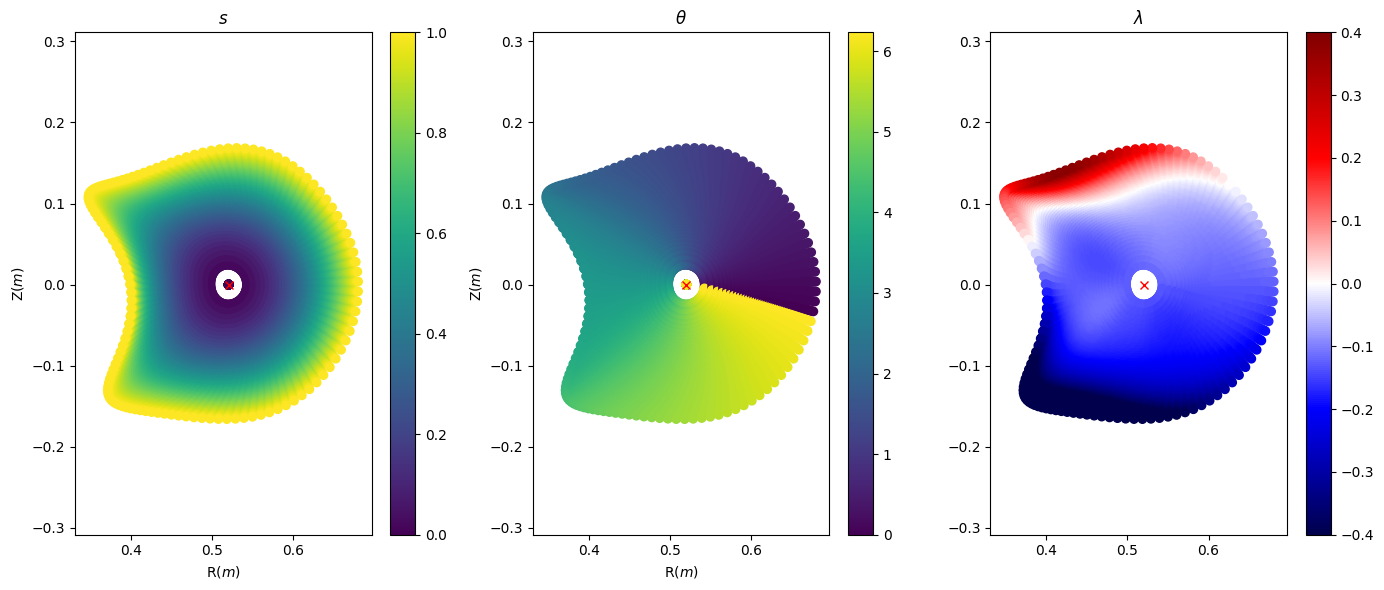

In [11]:
fig, axes = plt.subplots(nrows=1, ncols=3, sharex=True, figsize=(14, 6),
                         squeeze=False)

ax = axes[0][0]
cf = ax.scatter( R[:,:,phi_idx],Z[:,:,phi_idx],c=s[:,:,phi_idx] )
ax.plot( raxis[phi_idx], zaxis[phi_idx], 'rx')
ax.axis("equal")
ax.set_xlabel(r"R($m$)")
ax.set_ylabel(r"Z($m$)")
ax.set_title(r"$s$")
fig.colorbar(cf, ax=ax)

ax = axes[0][1]
cf = ax.scatter(R[:,:,phi_idx],Z[:,:,phi_idx],
                c=t[:,:,phi_idx])
fig.colorbar(cf, ax=ax)
ax.plot( raxis[phi_idx], zaxis[phi_idx], 'rx')
ax.axis("equal")
ax.set_xlabel(r"R($m$)")
ax.set_ylabel(r"Z($m$)")
ax.set_title(r"$\theta$")
ax = axes[0][2]
# Strictly speaking this is wrong as lambda_half is on the half grid ...
cf = ax.scatter(R[:,:,phi_idx],Z[:,:,phi_idx],
                c=lambda_half[:,:,phi_idx] , vmin = -0.4, vmax=0.4, cmap = "seismic")
ax.plot( raxis[phi_idx], zaxis[phi_idx], 'rx')
ax.axis("equal")
fig.colorbar(cf, ax=ax)
ax.set_title(r"$\lambda$")
fig.tight_layout()

plt.show()

## A continuous fit for $R(s,\theta,\varphi)$ $Z(s,\theta,\varphi)$ and $\lambda(s,\theta,\varphi)$

The coefficients for $R$, $Z$ and $\lambda$ are given only on a discrete grid in $s$, so let's make them continuous by fitting a polynomial:

so far a few observations are
- fitting in $\sqrt{s}$ makes an excellent fit between $s=0..1$ but horrible oscillation outside (i.e. Jacobian becomes negative)
- fitting in $s$ makes a slower converging fit but the Jacobian tends to remain positive
- the problem with high order polynomial even if the Jacobian is positive is that they diverge quickly for $s>1$ which shows as kink in $s(R,Z,\varphi$ at $s=1$. This kink is difficult to then fit globally with a polynomial in $R$ and $Z$

Let's try to extend the flux coefficients beyond $s=1$ and put low weights so that the continuous $s$ fit does not diverge so quickly

In [12]:
degRho = 13
xm = wout.xm
xn = wout.xn

def RR_polyfit(x, c):
    r, theta, phi = x
    
    jac2d = np.cos( np.outer(  theta, xm) - np.outer(phi,xn)) ## jac2d is 2d, xm is 2nd dimension, theta 1st
    result = 0
    for i in range(degRho+1):
        result += r**i* (jac2d @ c[degRho - i ,:]) 
    return result

def ZZ_polyfit(x, c):
    r, theta, phi = x
    
    jac2d = np.sin( np.outer(  theta, xm) - np.outer(phi,xn)) ## jac2d is 2d, xm is 2nd dimension, theta 1st
    result = 0
    for i in range(degRho+1):
        result += r**i* (jac2d @ c[degRho - i ,:])  
    return result


def det_polyfit( x, cR, cZ):
    """ The determinant of the Jacobian """
    r, theta, phi = x
    jac2dcos = np.cos( np.outer(  theta, xm) - np.outer(phi,xn))
    jac2dsin = np.sin( np.outer(  theta, xm) - np.outer(phi,xn))
    drdrho = 0
    dzdrho = 0
    drdtheta = 0
    dzdtheta = 0
    for i in range(degRho+1):
        if i > 0:
            drdrho += i*r**(i-1)*(jac2dcos @ cR[degRho - i ,:])
            dzdrho += i*r**(i-1)*(jac2dsin @ cZ[degRho - i ,:])
        drdtheta += -r**i*( jac2dsin @ (cR[degRho - i ,:]*xm))
        dzdtheta +=  r**i*( jac2dcos @ (cZ[degRho - i ,:]*xm))
    return drdrho * dzdtheta - dzdrho * drdtheta

In [13]:
# CHOOSE extension
ext = 4
ext_num_s = int(ext*num_s )-1
# ext_num_s = num_s + 1
# ext_num_s = num_s
ext_grid_s = np.linspace(0, ext, ext_num_s, endpoint=True) # !! TAKE CARE THAT POINTS IN EXT_S OVERLAP S
# ext_grid_s = np.append(grid_s,[5]) # A point in "infinity"
# ext_grid_s = grid_s
s_ext, t_ext, p_ext = np.meshgrid( 
    ext_grid_s, grid_theta, grid_phi, indexing='ij')

# CHOOSE rho dependency
# Sqrt makes excellent error inside but lots of oscillation outside
rho = np.sqrt(s)
grid_rhoz = np.sqrt( grid_sz)
grid_rho = np.sqrt( grid_s)
ext_grid_rho = np.sqrt(ext_grid_s)
grid_rho_half = np.sqrt( vmec.s_half_grid)
rho_ext = np.sqrt( s_ext)
# rho = s**2
# rho_ext = s_ext ** 2
# grid_rhoz = grid_sz ** 2
# grid_rho = grid_s ** 2

# degr >= 13 makes good box with ext = 1.2
# rho = s 
# grid_rhoz = grid_sz
# grid_rho = grid_s
# ext_grid_rho = ext_grid_s
# grid_rho_half = vmec.s_half_grid
# rho_ext = s_ext


coords = np.vstack((rho.ravel(),t.ravel(), p.ravel()))
coords_ext = np.vstack((rho_ext.ravel(),t_ext.ravel(), p_ext.ravel()))


In [14]:
# Make sure grid_s is a part of ext_grid_s
# print( grid_s)
# print( ext_grid_s)

In [15]:
wout_rmnc_ext = np.zeros( (len(xm), ext_num_s))
wout_zmns_ext = np.zeros( (len(xm), ext_num_s))
# wout_lmns_ext = np.zeros( (len(xm), wout.ns + wout.ns))
wout_rmnc_ext[:,:wout.ns] = wout.rmnc
wout_zmns_ext[:,:wout.ns] = wout.zmns
# wout_lmns_ext[:,:wout.ns] = wout.lmns
drmncdrho = (wout.rmnc[:,-1] - wout.rmnc[:,-2])/(1-np.sqrt( grid_s[-2])) # The factor 2 comes from deriving in rho
dzmnsdrho = (wout.zmns[:,-1] - wout.zmns[:,-2])/(1-np.sqrt( grid_s[-2]))
idx10 = np.where( (xm == 1) & (xn == 0))[0][0]
damping_factor = 1
for i in range( num_s, ext_num_s):
    # # SUGGESTED EXTENSION FROM PAPER
    # wout_rmnc_ext[:,i] = wout.rmnc[:,-1]
    # wout_zmns_ext[:,i] = wout.zmns[:,-1]
    # wout_rmnc_ext[ idx10, i] *= ext_grid_s[i]**0.5
    # wout_zmns_ext[ idx10, i] *= ext_grid_s[i]**0.5 # sqrt seems to make the smallest kink in s(R)
    # # JUST LINEAR EXTENSION
    # wout_rmnc_ext[:,i] = 2*wout_rmnc_ext[:,i-1]-wout_rmnc_ext[:,i-2]
    # wout_zmns_ext[:,i] = 2*wout_zmns_ext[:,i-1]-wout_zmns_ext[:,i-2]
    # # Exponential dampening to ellipsis
    rho_t = (ext_grid_s[i]**0.5-1)
    wout_rmnc_ext[:,i] = wout.rmnc[:,-1] + drmncdrho[:] * rho_t *np.exp( - damping_factor*rho_t)
    wout_zmns_ext[:,i] = wout.zmns[:,-1] + dzmnsdrho[:] * rho_t *np.exp( - damping_factor*rho_t)
    wout_rmnc_ext[ idx10, i] = wout.rmnc[idx10,-1] + wout.rmnc[idx10,-1] * rho_t 
    wout_zmns_ext[ idx10, i] = wout.zmns[idx10,-1] + wout.zmns[idx10,-1] * rho_t 

In [16]:
print( 2*(ext_grid_s[num_s]**0.5-1), 1-np.sqrt( grid_s[-2]))

0.010282844129666735 0.010471492746840227


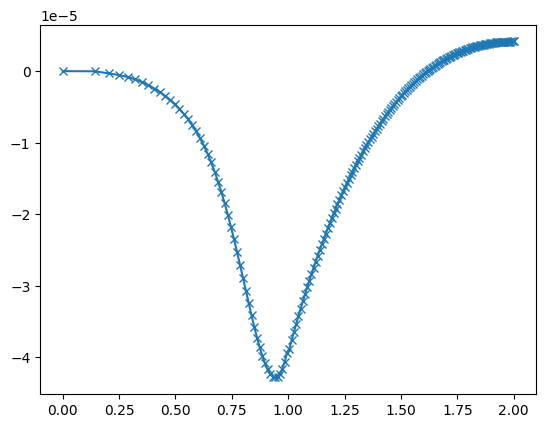

In [17]:
plt.plot( ext_grid_rho[:], wout_rmnc_ext[36,:], 'x-')
# print( drmncdrho[np.where( (xm == 1) & (xn == 0))],  wout.rmnc[np.where( (xm == 1) & (xn == 0)),-1])

In [18]:
R_ext = np.zeros( (ext_num_s,num_theta,num_phi))
Z_ext = np.zeros( (ext_num_s,num_theta,num_phi))
s_ext, t_ext, p_ext = np.meshgrid( ext_grid_s, grid_theta, grid_phi,indexing='ij')

for i in range(ext_num_s):
    for j in range( num_theta):
        for k in range( num_phi):
            # Arguments of Fourier series
            kernel =  grid_theta[j]*xm - grid_phi[k]*xn
            cosk = np.cos( kernel)
            sink = np.sin( kernel)

            R_ext[i,j,k] = np.dot( wout_rmnc_ext[:, i], cosk) # !! Note radius is 2nd dimension (i.e. transposed from NetCDF)!!
            Z_ext[i,j,k] = np.dot( wout_zmns_ext[:, i], sink)

s_ext.shape

(195, 128, 64)

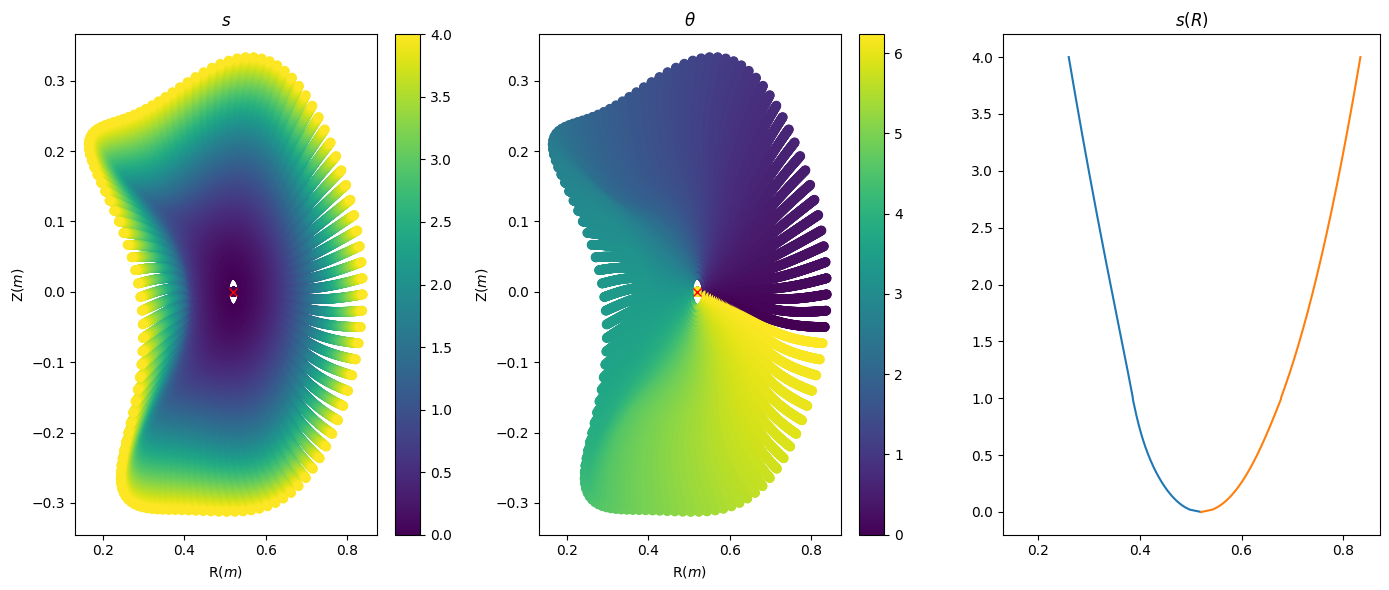

In [19]:
fig, axes = plt.subplots(nrows=1, ncols=3, sharex=True, figsize=(14, 6),
                         squeeze=False)

ax = axes[0][0]
cf = ax.scatter( R_ext[:,:,phi_idx],Z_ext[:,:,phi_idx],c=s_ext[:,:,phi_idx] )
ax.plot( raxis[phi_idx], zaxis[phi_idx], 'rx')
# ax.axis("equal")
# ax.set_xlim([R.min(), R.max()])
# ax.set_ylim([Z.min(), Z.max()])
ax.set_xlabel(r"R($m$)")
ax.set_ylabel(r"Z($m$)")
ax.set_title(r"$s$")
fig.colorbar(cf, ax=ax)

ax = axes[0][1]
cf = ax.scatter(R_ext[:,:,phi_idx],Z_ext[:,:,phi_idx],
                c=t_ext[:,:,phi_idx])
fig.colorbar(cf, ax=ax)
ax.plot( raxis[phi_idx], zaxis[phi_idx], 'rx')
# ax.axis("equal")
ax.set_xlabel(r"R($m$)")
ax.set_ylabel(r"Z($m$)")
ax.set_title(r"$\theta$")
ax = axes[0][2]
# Strictly speaking this is wrong as lambda_half is on the half grid ...
# cf = ax.scatter(R[:,:,phi_idx],Z[:,:,phi_idx],
#                 c=lambda_half[:,:,phi_idx] , vmin = -0.4, vmax=0.4, cmap = "seismic")
# ax.plot( raxis[phi_idx], zaxis[phi_idx], 'rx')
ax.plot( R_ext[:,int(num_theta/2),phi_idx], s_ext[:,int(num_theta/2),phi_idx])
ax.plot( R_ext[:,0,phi_idx], s_ext[:,0,phi_idx])
# ax.axis("equal")
# fig.colorbar(cf, ax=ax)
ax.set_title(r"$s(R)$")
fig.tight_layout()

plt.show()

In [20]:
 # THE FIT:
weights = np.ones( ext_num_s)
weights_half = np.ones( num_s-1)

# We do not care that the O-point is at the correct location 
# but we do care that we have an O-point a s=0
# This is guaranteed by having coeffs[ntor+1:0,0]== 0 in both R and Z
# The easiest way to do that is by forcing the fit through 0
for i in range( ext_num_s):
    if ext_grid_s[i] < 0.4:
        weights[i] = 1 # Changing this to 0.1 worsens the error by 10x
    if ext_grid_s[i] > 1.2:
        weights[i] = 0.1
weights[0] = 10
for i in range( num_s-1):
    if vmec.s_half_grid[i] < 0.4:
        weights_half[i] = 0.1
# weights[-1] = 0.1 # I think the last point is not good
fitR_coeffs = np.polyfit( ext_grid_rho, wout_rmnc_ext.transpose(), deg = degRho,
                        w = weights)
fitZ_coeffs = np.polyfit( ext_grid_rho, wout_zmns_ext.transpose(), deg = degRho,
                        w = weights)
fitL_coeffs = np.polyfit( grid_rho_half, wout.lmns[:,1:].transpose(), deg = degRho,
                        w = weights_half)
# Manually set the coefficients of axis
# This does not create a discontinuity but simply shifts the polynomials slightly up / down
fitR_coeffs[degRho,:]=wout.rmnc[:,0]
fitZ_coeffs[degRho,:]=wout.zmns[:,0]

In [21]:

# rmnc_fit = np.zeros_like( wout.rmnc)
# zmns_fit = np.zeros_like( wout.zmns)
rmnc_fit = np.zeros_like( wout_rmnc_ext)
zmns_fit = np.zeros_like( wout_zmns_ext)
lmns_fit = np.zeros_like( wout.lmns)
lmns_half_fit = np.zeros_like( wout.lmns) # Only to compare with wout.lmns
for k in range( wout.rmnc.shape[0]):
    rmnc_fit[k,:] = np.poly1d( fitR_coeffs[:,k])(ext_grid_rho)
    zmns_fit[k,:] = np.poly1d( fitZ_coeffs[:,k])(ext_grid_rho)
    # lmns_fit[k,:] = np.poly1d( fitL_coeffs[:,k])(vmec.s_full_grid)
    # lmns_half_fit[k,1:] = np.poly1d( fitL_coeffs[:,k])(vmec.s_half_grid)
    lmns_fit[k,:] = np.poly1d( fitL_coeffs[:,k])(grid_rho)
    lmns_half_fit[k,1:] = np.poly1d( fitL_coeffs[:,k])(grid_rho_half)
# for idx in range( 1,num_sz):
#     print( idx, np.linalg.norm( zmns_fit[idx,1:] - wout.zmns[idx,1:])/np.linalg.norm( wout.zmns[idx,1:]))
# print( np.linalg.norm( (rmnc_fit - wout.rmnc)*weights[None,:])/np.linalg.norm( wout.rmnc))
# print( np.linalg.norm( (zmns_fit - wout.zmns)*weights[None,:])/np.linalg.norm( wout.zmns))
print( np.linalg.norm( (rmnc_fit - wout_rmnc_ext)*weights[None,:])/np.linalg.norm( wout.rmnc))
print( np.linalg.norm( (zmns_fit - wout_zmns_ext)*weights[None,:])/np.linalg.norm( wout.zmns))
print( np.linalg.norm( (lmns_half_fit - wout.lmns)[:,1:]*weights_half[None,:])/np.linalg.norm( wout.lmns))

0.00036447022515284335
0.0014152494459789022
2.076110855929065e-05


In [22]:
# The 0 th element of zmns and rmnc is the axis
print( zmns_fit[0:wout.ntor+1,0])
print( wout.zmns[0:wout.ntor+1,0])
print( rmnc_fit[0:wout.ntor+1,0])
print( wout.rmnc[0:wout.ntor+1,0])

[ 0.00000000e+00 -4.50622992e-04  2.02012034e-06 -2.49994308e-07
  2.01709358e-07  1.02936432e-09 -1.40324370e-08]
[-0.00000000e+00 -4.50622992e-04  2.02012034e-06 -2.49994308e-07
  2.01709358e-07  1.02936432e-09 -1.40324370e-08]
[ 5.20257187e-01  3.21151259e-04  1.34449797e-06  2.49225057e-07
  1.38819714e-07  1.86592047e-07 -3.74926357e-08]
[ 5.20257187e-01  3.21151259e-04  1.34449797e-06  2.49225057e-07
  1.38819714e-07  1.86592047e-07 -3.74926357e-08]


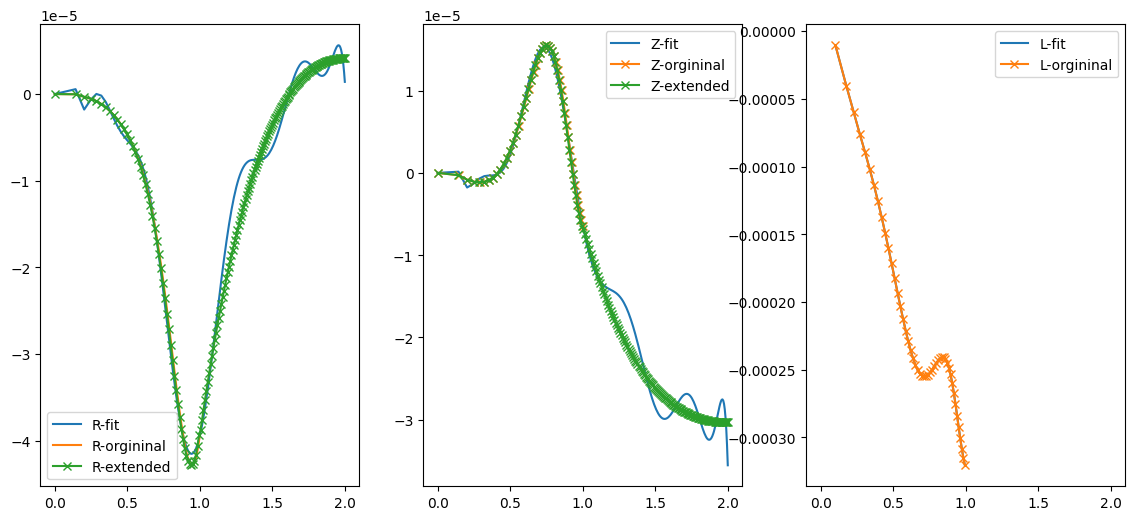

In [23]:

idx = 36
fig, axes = plt.subplots(nrows=1, ncols=3, sharex=True, figsize=(14, 6), squeeze=False)

ax = axes[0][0]
ax.plot( ext_grid_rho, rmnc_fit[idx,:], label = 'R-fit')
ax.plot( grid_rho, wout.rmnc[idx,:], '-', label = 'R-orgininal')
ax.plot( ext_grid_rho, wout_rmnc_ext[idx,:], 'x-', label = 'R-extended')
ax.legend()
# print( "Error for idx ", idx, np.linalg.norm( rmnc_fit[idx,:] - wout.rmnc[idx,:])/
#        np.linalg.norm( wout.rmnc[idx,:]))
ax = axes[0][1]
ax.plot( ext_grid_rho, zmns_fit[idx,:], label = 'Z-fit')
ax.plot( grid_rho, wout.zmns[idx,:], 'x-', label = 'Z-orgininal')
ax.plot( ext_grid_rho, wout_zmns_ext[idx,:], 'x-', label = 'Z-extended')
ax.legend()

ax = axes[0][2]
# ax.plot( vmec.s_half_grid, lmns_half_fit[idx,1:], label = 'L-fit')
# ax.plot( vmec.s_half_grid, wout.lmns[idx,1:], 'x-', label = 'L-orgininal')
ax.plot( grid_rho_half, lmns_half_fit[idx,1:], label = 'L-fit')
ax.plot( grid_rho_half, wout.lmns[idx,1:], 'x-', label = 'L-orgininal')
ax.legend()
plt.show()

In [24]:
R_fit = RR_polyfit(coords, fitR_coeffs)
R_fit = (R_fit).reshape(R.shape)
difference = R_fit - R 
print( difference.shape)
print(
    "Relative Error in R is      ",
    np.linalg.norm((difference*weights[:num_s,None,None]).ravel(), ord=2) / 
    np.linalg.norm(R.ravel(), ord=2),
)
Z_fit = ZZ_polyfit(coords, fitZ_coeffs)
Z_fit = (Z_fit).reshape(Z.shape)
difference = Z_fit - Z
print( difference.shape)
print(
    "Relative Error in Z is      ",
    np.linalg.norm((difference*weights[:num_s,None,None]).ravel(), ord=None) / np.linalg.norm(Z.ravel(), ord=None),
)


(49, 128, 64)
Relative Error in R is       0.000992972349362865
(49, 128, 64)
Relative Error in Z is       0.005306179354448863


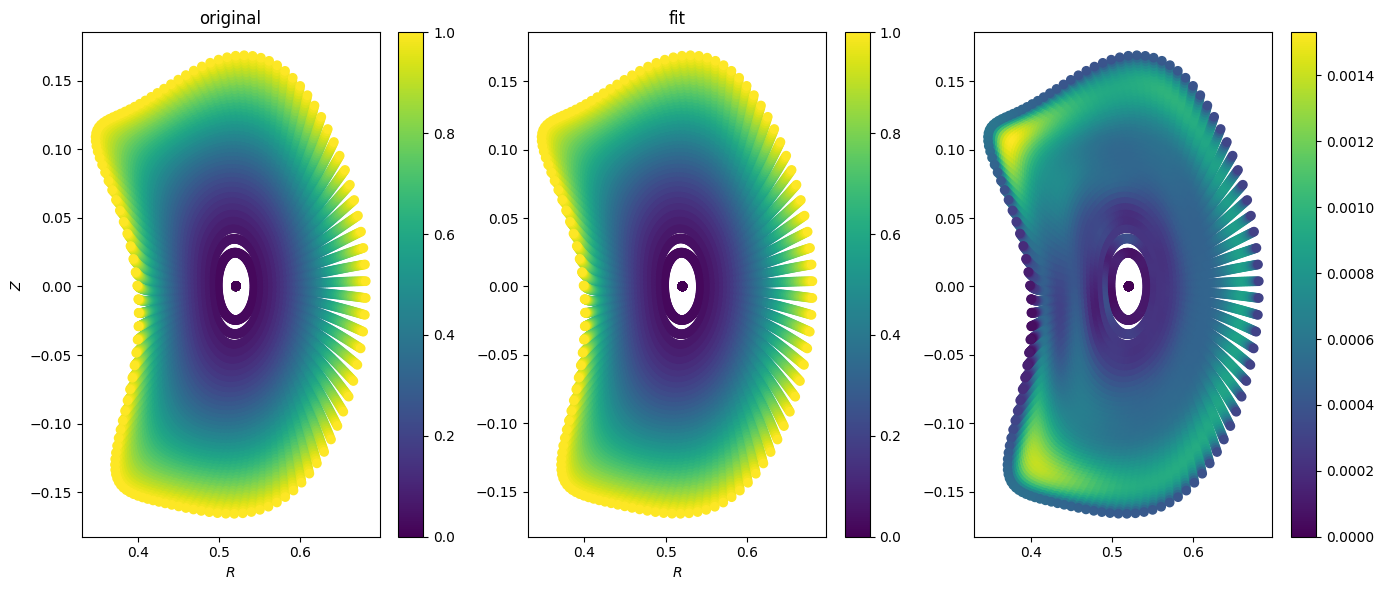

In [25]:
# Plot s in r, theta, phi coordinates
fig, axes = plt.subplots(nrows=1, ncols=3, sharex=True, figsize=(14, 6), squeeze=False)

ax = axes[0][0]
cf = ax.scatter( R[:,:,phi_idx],Z[:,:,phi_idx],c=s[:,:,phi_idx])
ax.set_xlabel(r"$R$")
ax.set_ylabel(r"$Z$")
ax.set_title(r"original")
fig.colorbar(cf, ax=ax)
ax = axes[0][1]

cf = ax.scatter( R_fit[:,:,phi_idx],Z_fit[:,:,phi_idx],c=s[:,:,phi_idx])
ax.set_xlabel(r"$R$")
ax.set_title(r"fit")

fig.colorbar(cf, ax=ax)
ax = axes[0][2]
cf = ax.scatter(R_fit[:,:,phi_idx],Z_fit[:,:,phi_idx],c=np.sqrt( 
    (R-R_fit)**2 + (Z - Z_fit)**2)[:,:,phi_idx])
fig.colorbar(cf, ax=ax)
fig.tight_layout()

plt.show()

Before we can extend we should make sure that the Jacobian does not vanish!

In [26]:
R_ext_fit = RR_polyfit(coords_ext, fitR_coeffs)
R_ext_fit = (R_ext_fit).reshape(s_ext.shape)
Z_ext_fit = ZZ_polyfit(coords_ext, fitZ_coeffs)
Z_ext_fit = (Z_ext_fit).reshape(s_ext.shape)

detJ_fit = det_polyfit( coords, fitR_coeffs, fitZ_coeffs).reshape( R_fit.shape)
detJ_ext_fit = det_polyfit( coords_ext, fitR_coeffs, fitZ_coeffs).reshape( s_ext.shape)

The minimum determinant may not be <= 0:  0.0032328541351282795


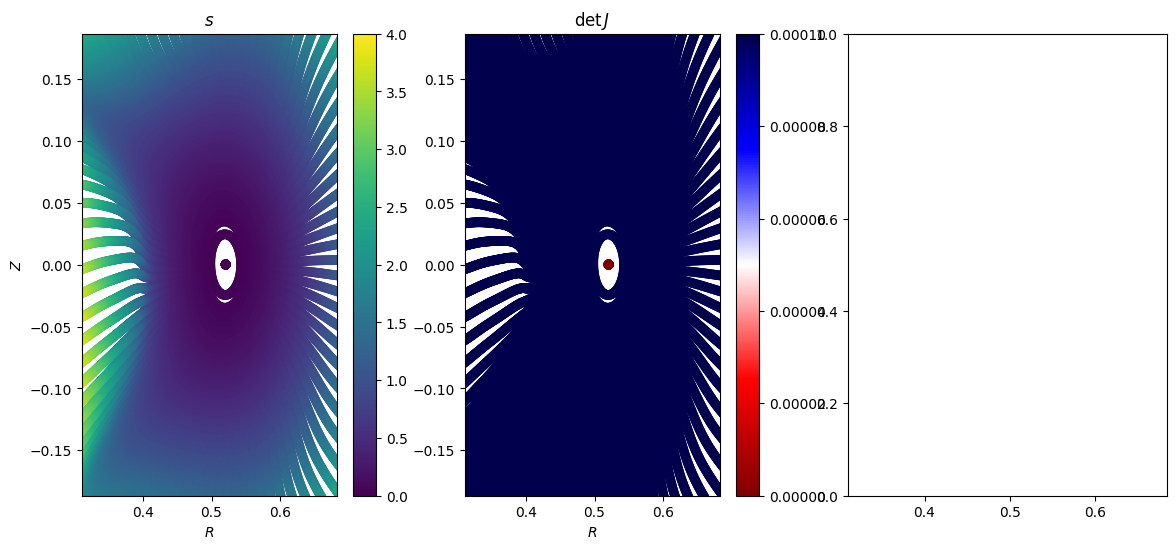

In [27]:
# Plot s in r, theta, phi coordinates
fig, axes = plt.subplots(nrows=1, ncols=3, sharex=True, figsize=(14, 6), squeeze=False)

ax = axes[0][0]
cf = ax.scatter( R_ext_fit[:,:,phi_idx],Z_ext_fit[:,:,phi_idx],c=s_ext[:,:,phi_idx])
# ax.plot( raxis, zaxis, 'rx')
# ax.axis("equal")
ax.set_xlabel(r"$R$")
ax.set_ylabel(r"$Z$")
ax.set_title(r"$s$")
ax.set_xlim([R.min(), R.max()])
ax.set_ylim([Z.min(), Z.max()])
fig.colorbar(cf, ax=ax)
ax = axes[0][1]

cf = ax.scatter( R_ext_fit[:,:,phi_idx],Z_ext_fit[:,:,phi_idx],c=detJ_ext_fit[:,:,phi_idx],
               vmin = 0, vmax = 1e-4, cmap = "seismic_r")
ax.set_xlim([R.min(), R.max()])
ax.set_ylim([Z.min(), Z.max()])
ax.set_xlabel(r"$R$")
ax.set_title(r"$\det J$")
fig.colorbar(cf, ax=ax)
# # ax.plot( raxis, zaxis, 'rx')
# # ax.axis("equal")
# # ax.set_xlabel(r"R($m$)")
# # ax.set_ylabel(r"Z($m$)")
# # ax.set_title(r"$\tilde \theta$")
# ax = axes[0][2]
# cf = ax.scatter(R[:,:,phi_idx],Z[:,:,phi_idx],c=np.sqrt( 
#     (R-R_fit)**2 + (Z - Z_fit)**2)[:,:,phi_idx], cmap = "seismic")
# # ax.plot( raxis, zaxis, 'rx')
# # ax.axis("equal")
# fig.colorbar(cf, ax=ax)
# # ax.set_title(r"$\lambda$")
# fig.tight_layout()
print( "The minimum determinant may not be <= 0: ", detJ_ext_fit[1:,:,:].min())
plt.show()

The extension is difficult to keep single valued for $\sqrt{s}$ expansion!

If we continue with a fit in polar coordinates the only thing we need is a continuously differentiable function in $0\leq s \leq 1$.
Then, we can re-compute $R$, $Z$ and $\lambda$ for a fit in polar coordinates:

Theoretically, we could now increase the number of points in $s$ or $\rho$ but for now let's continue as is!

## Direct coordinate inversion

Instead of trying to fit $s(R,Z,\varphi)$ directly we can try to write a function that
computes $s(R,Z,\varphi)$ via  coordinate inveresion. This is possible because we now have
a continuously differentiable continuation of $R(s,\theta,\varphi)$ and $Z(s,\theta,\varphi)$.


In [28]:
a2 = wout.rmnc[ np.where( (xm == 1) & (xn == 0)), -1]*\
         wout.zmns[ np.where( (xm == 1) & (xn == 0)), -1]
print(a2[0][0])

0.024530417877528826


In [29]:
def magneticAxis( P):
    raxis = np.dot( np.cos( -np.outer( P, tor_modes)), wout.raxis_cc)
    zaxis = np.dot( np.sin( -np.outer( P, tor_modes)), wout.zaxis_cs)
    return raxis.reshape(P.shape),zaxis.reshape(P.shape)

def J_polyfit( r, theta, phi, cR, cZ):
    """ The determinant of the Jacobian """
    # r, theta, phi = x
    jac2dcos = np.cos( np.outer(  theta, xm) - np.outer(phi,xn))
    jac2dsin = np.sin( np.outer(  theta, xm) - np.outer(phi,xn))
    R = 0
    Z = 0
    drdrho = 0
    dzdrho = 0
    drdtheta = 0
    dzdtheta = 0
    for i in range(degRho+1):
        R += r**i*(jac2dcos @ cR[degRho - i ,:]).reshape(r.shape)
        Z += r**i*(jac2dsin @ cZ[degRho - i ,:]).reshape(r.shape)
        if i > 0:
            drdrho += i*r**(i-1)*(jac2dcos @ cR[degRho - i ,:]).reshape(r.shape)
            dzdrho += i*r**(i-1)*(jac2dsin @ cZ[degRho - i ,:]).reshape(r.shape)
        drdtheta += -r**i*( jac2dsin @ (cR[degRho - i ,:]*xm)).reshape(r.shape)
        dzdtheta +=  r**i*( jac2dcos @ (cZ[degRho - i ,:]*xm)).reshape(r.shape)
    return R,Z.reshape(r.shape),\
        drdrho.reshape(r.shape),drdtheta.reshape(r.shape),\
        dzdrho.reshape(r.shape),dzdtheta.reshape(r.shape)
    
def inverse( R, Z, P, eps = 1e-6, max_step = 100):
    """ Let's assume R, Z, P are arrays
    Pay attention to whether the polynomial is in s or sqrt(s)
    """
    if not isinstance(R, np.ndarray):
        R = np.array([R])
        Z = np.array([Z])
        P = np.array([P])
    raxis,zaxis = magneticAxis(P)
    Rb = R - raxis
    Zb = Z - zaxis
    # Construct initial guess
    radius2 = Rb**2 + Zb**2
    a2 = (wout.rmnc[ np.where( (xm == 1) & (xn == 0)), -1]*\
         wout.zmns[ np.where( (xm == 1) & (xn == 0)), -1])[0][0]
    # s0 = radius2/a2
    s0 = np.sqrt( radius2/a2) # IF POLYNOMIAL FITS IN sqrt(s)
    t0 = np.atan2( Zb , Rb)
    t0 = np.where( t0 < 0 , t0 + 2*np.pi, t0)
    # Setup Newton iteration
    delta = 1e300
    delta1 = 1e300
    beta = 1
    tau = 1e300
    tau1 = 1e300
    
    for i in range( max_step):
        # coords = np.vstack((s0.ravel(),t0.ravel(), P.ravel()))
        Rr,Zr,drdrho,drdtheta,dzdrho,dzdtheta = \
            J_polyfit( s0, t0, P, fitR_coeffs, fitZ_coeffs)
        dR = Rr - R
        dZ = Zr - Z
        delta1 = delta
        delta = np.sum( np.sqrt( dR**2 + dZ**2))/np.sum( np.sqrt( R**2 + Z**2))
        # print( i, delta)
        if delta < eps:
            break
        tau1 = tau
        tau = drdrho*dzdtheta - drdtheta*dzdrho
        if i == 0:
            tau1 = tau
        if delta > delta1:
            tau = 0.75*tau1 + 0.25*tau
            beta = beta/2
        else:
            beta =1
        s0 = np.where( tau == 0, s0, s0 - beta*(dzdtheta*dR - drdtheta*dZ)/tau)
        t0 = np.where( tau == 0, t0, t0 - beta*(drdrho*dZ - dzdrho*dR)/tau)
        s0 = np.where( s0 < 0, -s0 , s0)
        t0 = np.where( s0 < 0, t0 + np.pi, t0)
        t0 = np.where( t0 < 0, t0 + 2*np.pi, t0)
        t0 = t0 % (2*np.pi)
    return s0,t0,P

In [30]:
# A first test
(s0,t0,p0) = inverse( 0.6,0,grid_phi[phi_idx])
print( s0, t0, RR_polyfit( (s0,t0,p0), fitR_coeffs),
       ZZ_polyfit( (s0,t0,p0), fitZ_coeffs))


[0.50243931] [0.12953438] [0.6] [-9.11360422e-11]


In [31]:
# What happens at the O-point
(s0,t0,p0) = inverse( raxis[phi_idx], zaxis[phi_idx], grid_phi[phi_idx])
print(s0, t0, RR_polyfit( (s0,t0,p0), fitR_coeffs),
       ZZ_polyfit( (s0,t0,p0), fitZ_coeffs))
# The O-point is found in one step ...

[7.08855592e-16] [6.28294117] [0.52055489] [0.00017106]


In [32]:
# A difficult point
R0 = np.array([0.33581544058827123])
Z0 = np.array([-0.16079339171452933])
P0 = np.array([0.11584622910112363])
(s0,t0,p0) = inverse( R0, Z0, P0, eps = 1e-6)
print( s0,t0,p0, RR_polyfit( (s0,t0,p0), fitR_coeffs),
       ZZ_polyfit( (s0,t0,p0), fitZ_coeffs))

[1.2634484] [4.19607173] [0.11584623] [0.33581544] [-0.16079339]


In [33]:
# All at once
R0 = np.array([0.33581544058827123,  raxis[phi_idx], 0.6])
Z0 = np.array([-0.16079339171452933,  zaxis[phi_idx], 0 ])
P0 = np.array([0.11584622910112363,  grid_phi[phi_idx], grid_phi[phi_idx]])
print( R0)
(s0,t0,p0) = inverse( R0, Z0, P0)
print( s0,t0,p0, RR_polyfit( (s0,t0,p0), fitR_coeffs),
       ZZ_polyfit( (s0,t0,p0), fitZ_coeffs))

[0.33581544 0.52055489 0.6       ]
[1.26344567 0.         0.50243931] [4.19607285 0.         0.12953438] [0.11584623 0.07853982 0.07853982] [0.33581574 0.52055489 0.6       ] [-1.60793176e-01  1.71055739e-04 -1.37998608e-16]


/tmp/ipykernel_14844/815627914.py:75: RuntimeWarning: invalid value encountered in divide
  s0 = np.where( tau == 0, s0, s0 - beta*(dzdtheta*dR - drdtheta*dZ)/tau)
/tmp/ipykernel_14844/815627914.py:76: RuntimeWarning: divide by zero encountered in divide
  t0 = np.where( tau == 0, t0, t0 - beta*(drdrho*dZ - dzdrho*dR)/tau)


In [34]:
# Let's set up a Legendre polynomial interpolant in R and Z
degR = 14
degZ = 14
g3d_inter = dg.Grid([ R.min(),
                Z.min(),
                0-np.pi/wout.nfp/num_phi], # - h/2
              [ R.max(),
                Z.max(),
                2*np.pi/wout.nfp-np.pi/wout.nfp/num_phi], # -h/2
              [degR,degZ,1], [1, 1, num_phi])
r3d_inter = dg.evaluate( lambda x,y,z: x, g3d_inter).reshape(g3d_inter.shape)
z3d_inter = dg.evaluate( lambda x,y,z: y, g3d_inter).reshape(g3d_inter.shape)
p3d_inter = dg.evaluate( lambda x,y,z: z, g3d_inter).reshape(g3d_inter.shape)
s3d_inter = np.zeros_like( r3d_inter)
t3d_inter = np.zeros_like( z3d_inter)
(s3d_inter,t3d_inter,p3d_inter) = inverse(
        r3d_inter, z3d_inter, p3d_inter)
    # print( r3d_inter[i], z3d_inter[i], p3d_inter[i], s3d_inter[i], t3d_inter[i])

In [35]:
# Set up a grid for interpolating values
g2d = dg.Grid([ R.min(),
                Z.min()], # - h/2
              [ R.max(),
                Z.max()], # -h/2
              [3,3], [80, 80])
r2d = dg.evaluate( lambda x,y: x, g2d).reshape(g2d.shape)
z2d = dg.evaluate( lambda x,y: y, g2d).reshape(g2d.shape)

In [36]:
# Forward and Backward transformation of Legendre polynomial
(x_,w_) = np.polynomial.legendre.leggauss( g3d_inter.n[0])
backward0 = np.polynomial.legendre.legvander( x_, g3d_inter.n[0]-1)
forward0 = np.linalg.inv(backward0)
(x_,w_) = np.polynomial.legendre.leggauss( g3d_inter.n[1])
backward1 = np.polynomial.legendre.legvander( x_, g3d_inter.n[1]-1)
forward1 = np.linalg.inv(backward1)

# Evaluate at some R, Z, value
R0n = 2*(r2d - g3d_inter.x0[0])/g3d_inter.lx()[0]-1
Z0n = 2*(z2d - g3d_inter.x0[1])/g3d_inter.lx()[1]-1 # Normalize [-1,1]

vander0 = np.polynomial.legendre.legvander( R0n, g3d_inter.n[0]-1)@forward0 
vander1 = np.polynomial.legendre.legvander( Z0n, g3d_inter.n[1]-1)@forward1 
print((vander1@forward1).shape)
# This Multiplies 
s3d = np.zeros( (g2d.shape[0], g2d.shape[1], g3d_inter.shape[2]) )
t3d = np.zeros( (g2d.shape[0], g2d.shape[1], g3d_inter.shape[2]) )
for i in range( g2d.shape[0]):
    for j in range( g2d.shape[1]):
        s3d[i,j,:] = np.einsum('k,l,klm->m', vander0[i,j,:], vander1[i,j,:], s3d_inter)
        t3d[i,j,:] = np.einsum('k,l,klm->m', vander0[i,j,:], vander1[i,j,:], t3d_inter)
# s3d_back = np.einsum('ik,jl,klm->ijm', backward0, backward1, s3d_leg)
# s3d_back[:,:,-1]
# np.einsum( 'i,j,ijk->k', px[0], px[1], s3d_leg)

(240, 240, 14)


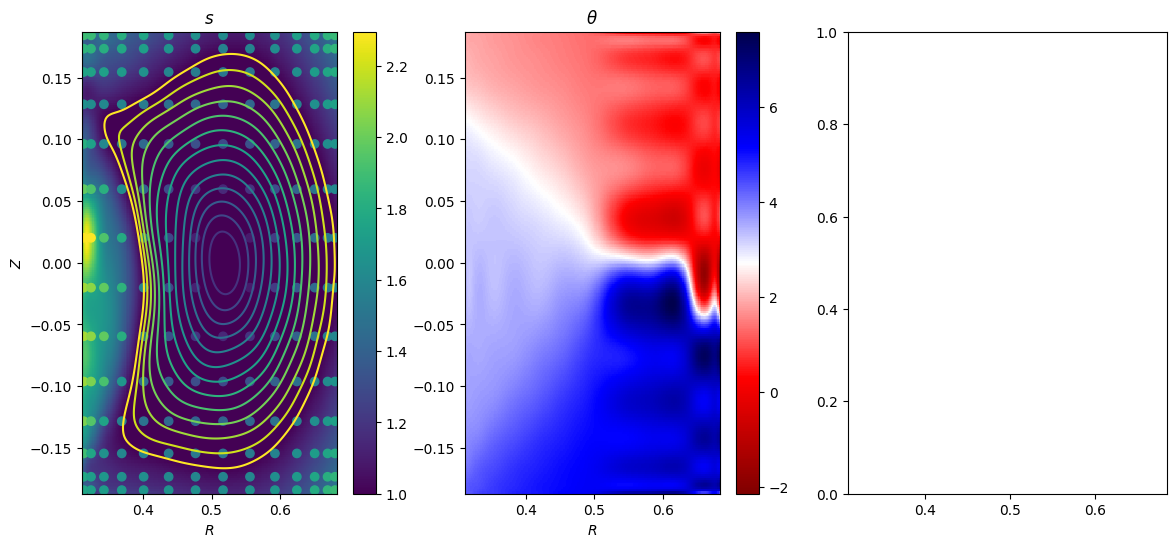

In [37]:

fig, axes = plt.subplots(nrows=1, ncols=3, sharex=True, figsize=(14, 6), squeeze=False)

ax = axes[0][0]
cf = ax.pcolormesh( r2d[:,:],z2d[:,:],s3d[:,:,phi_idx],vmin = 1)
levels = np.linspace( 0, 1, 15)
ax.contour(r2d,z2d, s3d[:,:,phi_idx], levels)
# ax.scatter( R_ext_fit[:2*49,:,phi_idx],Z_ext_fit[:2*49,:,phi_idx],c=s_ext[:2*49,:,phi_idx])
ax.scatter( r3d_inter[:,:,phi_idx],z3d_inter[:,:,phi_idx],c=s3d_inter[:,:,phi_idx])
ax.set_xlabel(r"$R$")
ax.set_ylabel(r"$Z$")
ax.set_title(r"$s$")
# ax.set_xlim([R.min(), R.max()])
# ax.set_ylim([Z.min(), Z.max()])
fig.colorbar(cf, ax=ax)
ax = axes[0][1]

cf = ax.pcolormesh( r2d[:,:],z2d[:,:],t3d[:,:,phi_idx],
               cmap = "seismic_r")
# ax.set_xlim([R.min(), R.max()])
# ax.set_ylim([Z.min(), Z.max()])
ax.set_xlabel(r"$R$")
ax.set_title(r"$\theta$")
fig.colorbar(cf, ax=ax)
# # ax.plot( raxis, zaxis, 'rx')
# # ax.axis("equal")
# # ax.set_xlabel(r"R($m$)")
# # ax.set_ylabel(r"Z($m$)")
# # ax.set_title(r"$\tilde \theta$")
# ax = axes[0][2]
# cf = ax.scatter(R[:,:,phi_idx],Z[:,:,phi_idx],c=np.sqrt( 
#     (R-R_fit)**2 + (Z - Z_fit)**2)[:,:,phi_idx], cmap = "seismic")
# # ax.plot( raxis, zaxis, 'rx')
# # ax.axis("equal")
# fig.colorbar(cf, ax=ax)
# # ax.set_title(r"$\lambda$")
# fig.tight_layout()
plt.show()

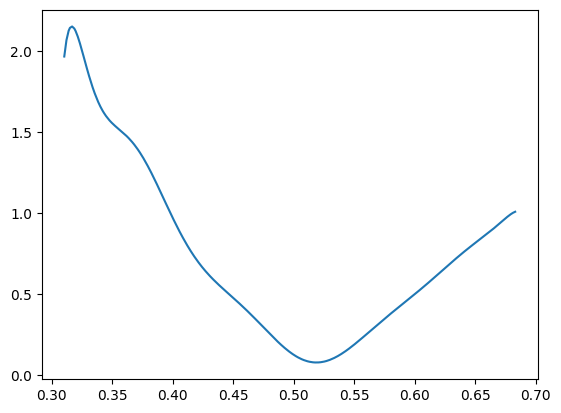

In [38]:
plt.plot( r2d[:,int(r2d.shape[1]/2)], s3d[:,int(r2d.shape[1]/2),phi_idx])

## A fit in polar coordinates

It turns out that directly fitting a 2d polynomial in R and Z coordinates has several disadvantages

- first and foremost it is unclear how to preserve stellarator symmetry in both $s$ and $\lambda$
- specifically for $s$ it is not trivial to preserve the location of the O-point even if the first two coefficients in $R$ and $Z$ are zeroed. The higher order fields can potentially make a second or third O-point.
- also for $s$ oscillations that appear outside the LCFS are detrimental to the solution if we intend to use it in simulations where we need to define flux aligned walls

This is why we here decide to use polar coordinates for the fit. 
 - Fitting $\sqrt{s}$ instead of $s$ vastly improves or entirely removes oscillations outside the LCFS. This is likely because there is an almost linear relation between $\sqrt{s}$ and $r$

In [39]:
s_ijk, t_ijk, p_ijk = np.meshgrid( grid_sz, grid_theta, grid_phi,indexing='ij')
R_ijk = R_fit.copy()
Z_ijk = Z_fit.copy()
L_fit = ZZ_polyfit(coords, fitL_coeffs).reshape( R_ijk.shape)
L_ijk = L_fit.copy()

# s_ijk, t_ijk, p_ijk = np.meshgrid( grid_sz, grid_theta, grid_phi,indexing='ij')
# R_ijk = R.copy()
# Z_ijk = Z.copy()
# L_fit = ZZ_polyfit(coords, fitL_coeffs).reshape( R_ijk.shape)
# L_ijk = L_fit.copy()

In [40]:
# Create radius and angle

# The radius
radius_ijk = np.zeros( (num_sz, num_theta, num_phi))
for k in range( num_phi):
    radius_ijk[:,:,k] = np.sqrt( (R_ijk[1:,:,k]-raxis[k])**2 + (Z_ijk[1:,:,k]-zaxis[k])**2)
# The geometric angle
theta_gijk = np.zeros( (num_sz, num_theta, num_phi))
for k in range( num_phi):
    theta_gijk[:,:,k] = np.where( Z_ijk[1:,:,k] >= zaxis[k],
                    np.arccos( (R_ijk[1:,:,k]-raxis[k]) / radius_ijk[:,:,k]), 
            2*np.pi-np.arccos( (R_ijk[1:,:,k]-raxis[k]) / radius_ijk[:,:,k]))

# We have to manually set the angle for s=0
# for j in range( num_theta):
#     theta_g[0,j] = grid_theta[j]
# and the angle for the last one
# for i in range( num_s):
#     theta_g[i,num_theta-1] = 2*np.pi

# theta_g

In [41]:
#  Create tilde theta
# through repeated plotting and modification we found this form to be the best definition: 

tilde_lambda_ijk = np.where( t_ijk+L_ijk[1:] - theta_gijk < -np.pi ,
                   t_ijk+L_ijk[1:] - theta_gijk+2*np.pi,
         np.where( t_ijk+L_ijk[1:] - theta_gijk > np.pi,
                   t_ijk+L_ijk[1:] - theta_gijk -2*np.pi,
                   t_ijk+L_ijk[1:] - theta_gijk ))
L_ijk.shape
# tilde_lambda_ijk = np.where( t_ijk - theta_gijk < -np.pi ,
#                    t_ijk - theta_gijk+2*np.pi,
#          np.where( t_ijk - theta_gijk > np.pi,
#                    t_ijk - theta_gijk -2*np.pi,
#                    t_ijk - theta_gijk ))

# tilde_lambda_ijk = lambda_ijk

(49, 128, 64)

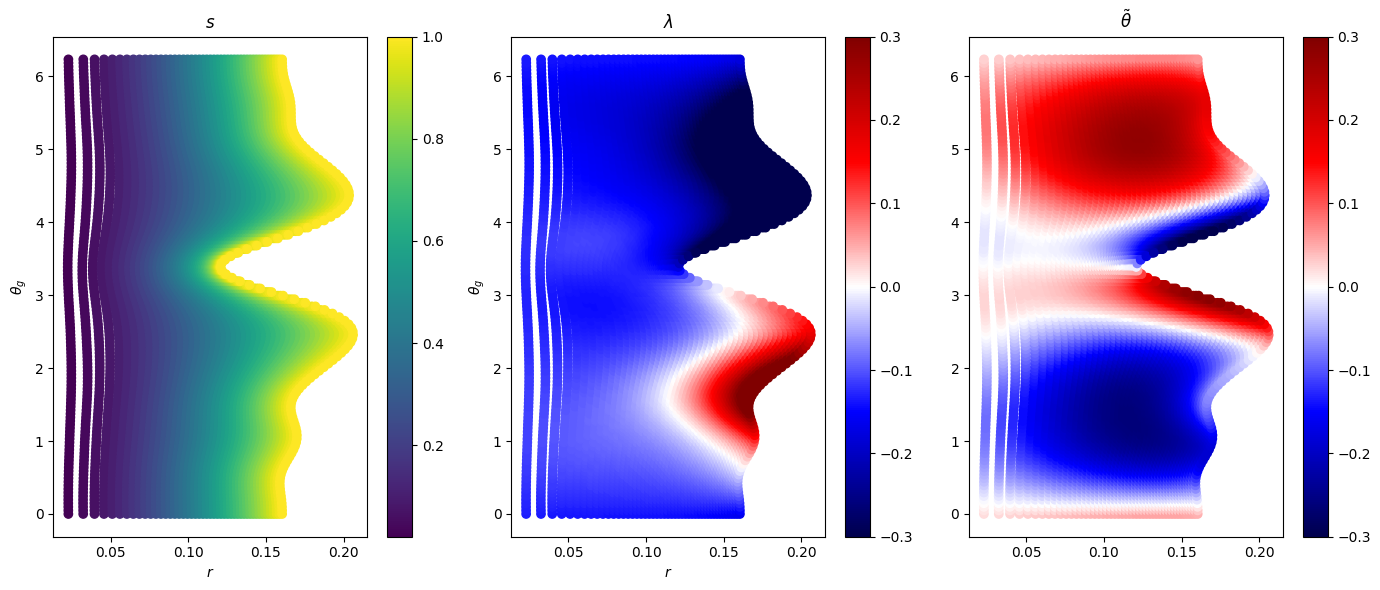

In [42]:
fig, axes = plt.subplots(nrows=1, ncols=3, sharex=True, figsize=(14, 6), squeeze=False)

ax = axes[0][0]
# cf = ax.contour(r, z, psip, 15)
# ax.clabel(cf)
cf = ax.scatter( radius_ijk[:,:,phi_idx],t_ijk[:,:,phi_idx],c=s_ijk[:,:,phi_idx])
# ax.axis("equal")
fig.colorbar(cf, ax=ax)
ax.set_xlabel(r"$r$")
ax.set_ylabel(r"$\theta_g$")
ax.set_title(r"$s$")
ax = axes[0][1]
# cf = ax.contour(r_rz, theta_g, (theta_rz),300)
# cf = ax.scatter(r_rz, theta_g, c=(theta_rz+lambda_rz))
cf = ax.scatter(radius_ijk[:,:,phi_idx],t_ijk[:,:,phi_idx], c=L_ijk[1:,:,phi_idx],
                vmin = -0.3, vmax=0.3, cmap = "seismic")
fig.colorbar(cf, ax=ax)
# ax.axis("equal")
ax.set_xlabel(r"$r$")
ax.set_ylabel(r"$\theta_g$")
ax.set_title(r"$\lambda$")

ax = axes[0][2]
cf = ax.scatter(radius_ijk[:,:,phi_idx],t_ijk[:,:,phi_idx],
                c=tilde_lambda_ijk[:,:,phi_idx], vmin = -0.3, vmax=0.3, cmap = "seismic")
fig.colorbar(cf, ax=ax)
ax.set_title(r"$\tilde \theta$")
fig.tight_layout()

plt.show()

angle  1.9634954084936207


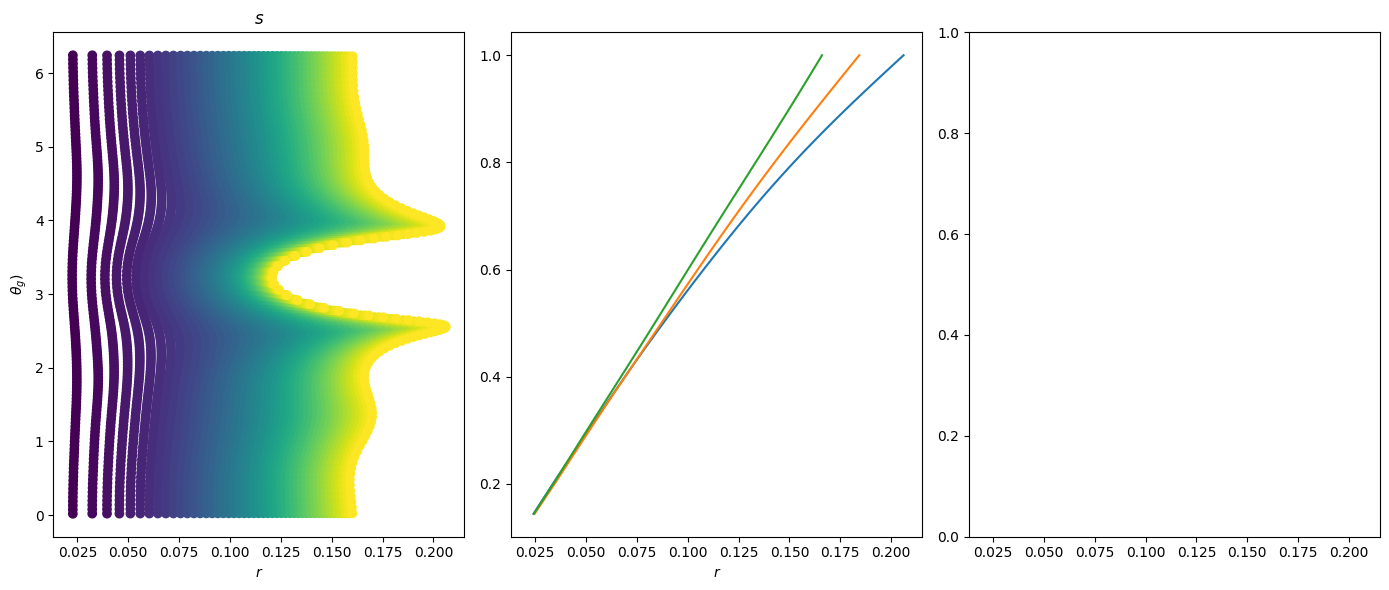

In [43]:
# This plot shows that sqrt(s) is better to fit because is almost linear in r

# Plot s in r, theta, phi coordinates
fig, axes = plt.subplots(nrows=1, ncols=3, sharex=True, figsize=(14, 6), squeeze=False)

ax = axes[0][0]
ax.scatter( radius_ijk[:,:,phi_idx],theta_gijk[:,:,phi_idx],c=s_ijk[:,:,phi_idx])
# ax.plot( raxis, zaxis, 'rx')
# ax.axis("equal")
ax.set_xlabel(r"$r$")
ax.set_ylabel(r"$\theta_g$)")
ax.set_title(r"$s$")
ax = axes[0][1]
rs = np.linspace(0.01, 0.2, 30)
# ss = 4*rs**2
if num_phi > 32:
    ax.plot( radius_ijk[:,50,phi_idx], np.sqrt(s_ijk[:,50,phi_idx]))
    ax.plot( radius_ijk[:,40,phi_idx], np.sqrt(s_ijk[:,40,phi_idx]))
    ax.plot( radius_ijk[:,30,phi_idx], np.sqrt(s_ijk[:,30,phi_idx]))
    print( "angle ", grid_theta[40])
# ax.plot( rs, np.sqrt(ss), 'r-')
ax.set_xlabel(r"$r$")
# ax.axis("equal")
# ax.set_xlim([0.01,0.2])
# ax.set_xscale("log")
# ax.set_yscale("log")

# # cf = ax.contour(r, z, (theta_rz),300)
# # cf = ax.scatter(r, z, c=(theta_rz+lambda_rz))
# cf = ax.scatter(r, z, c=np.where( theta_rz- theta_g < -np.pi ,theta_rz- theta_g+2*np.pi,
#                                   np.where( theta_rz - theta_g > np.pi, theta_rz- theta_g -2*np.pi,
#                                             theta_rz - theta_g )))#,
#                 # vmin = -0.3, vmax=0.3, cmap = "seismic")
# # cf = ax.scatter(r, z, c=((theta_rz+lambda_rz-theta_g)%(2*np.pi)))
# fig.colorbar(cf, ax=ax)
# ax.plot( raxis, zaxis, 'rx')
# ax.axis("equal")
# ax.set_xlabel(r"R($m$)")
# ax.set_ylabel(r"Z($m$)")
# ax.set_title(r"$\tilde \theta$")
# ax = axes[0][2]
# cf = ax.scatter(r, z, c= lambda_rz, vmin = -0.3, vmax=0.3, cmap = "seismic")
# ax.plot( raxis, zaxis, 'rx')
# ax.axis("equal")
# fig.colorbar(cf, ax=ax)
# ax.set_title(r"$\lambda$")
fig.tight_layout()

plt.show()

In [44]:
# Now set up the fit in s
degr = 3
mpol = 8 # wout nice has 8, w7x has 12
ntor = 6 # wout nice has 6, w7x has 12
xm_l = []
xn_l = []

for i in range(mpol):
    for j in range(-ntor, ntor+1):
        if i == 0 and j < 0:
            continue
        else:
            xm_l.append(i)
            xn_l.append(j*wout.nfp)
modesK = len(xm_l)
xmm = np.array(xm_l)
xnn = np.array(xn_l)
c = np.array(np.zeros(degr * modesK ))

def s_fit(x, *c):
    """ The function to fit to the data """
    r, theta, phi = x
    
    jac2d = np.cos( np.outer(  theta, xmm) - np.outer(phi,xnn)) ## jac2d is 2d, xm is 2nd dimension, theta 1st
    result = 0
    for i in range(degr):
        # result += r**(2*i+2)* (jac2d @ c[i*modesK:(i+1)*modesK])
        result += r**(i+1)* (jac2d @ c[i*modesK:(i+1)*modesK])
    
    return result

def s_jac_fit(x, *c):
    """ Its Jacobian """
    r, theta, phi = x
    jac = np.zeros( (len(r), degr*modesK))
    for i in range(degr):
        for j in range(modesK):
            # jac[:, i*modesK+j] = r**(2*i+2)* np.cos( xmm[j]*theta - xnn[j]*phi)
            jac[:, i*modesK+j] = r**(i+1)* np.cos( xmm[j]*theta - xnn[j]*phi)
    
    return jac
    

def s_fct(R,Z,P):
    """ The function to fit to the data """
    rad = np.sqrt( R**2+Z**2)
    if rad == 0:
        rad = 1e-16
    if Z > 0:
        the = np.arccos ( R/rad)
    else:
        the = 2*np.pi-np.arccos (R/rad)
    
    jj = np.cos( the* xmm - P*xnn) ## jac2d is 2d, xm is 2nd dimension, theta 1st
    result = 0
    for i in range(degr):
        # result += rad**(2*i+2)* np.dot(jj, copt[i*modesK:(i+1)*modesK])
        result += rad**(i+1)* np.dot(jj, copt[i*modesK:(i+1)*modesK])
    
    return result**2

In [45]:
# print(wout.mpol, wout.ntor)
# print(xm, xmm)

In [46]:
# We need to ravel the meshgrids of X, Y points
# to a pair of 1-D arrays:
coords = np.vstack((radius_ijk.ravel(),theta_gijk.ravel(), p_ijk.ravel()))
# psip_exp = s_ijk.ravel()
psip_exp = np.sqrt( s_ijk.ravel())
#weights = s_ijk.ravel() # did not help too much (can even make it worse!)

In [47]:
# Solve linear least squares
A = s_jac_fit( coords, *c)
print("Shape of jacobian", A.shape)
# B = np.transpose(A)@A
# print( "Shape of J^T J ", B.shape)
# print(psip_exp.shape)
# lambdaB, eigenB = np.linalg.eigh(B)

# print( "Eigenvalues", lambdaB)
# print("Condition number ", np.linalg.cond(B))
import time
start = time.monotonic()
# clstsq,res,rank,singular = np.linalg.lstsq( A*weights[:,None], psip_exp*weights)
clstsq,res,rank,singular = np.linalg.lstsq( A, psip_exp)
stop = time.monotonic()
print( "Took ", stop - start, "s")
# print(singular)
copt = clstsq

Shape of jacobian (393216, 294)
Took  8.18473769800039 s


In [48]:
# # Solve direct optimisation with or without Jacobian (takes forever... and comes up with the same solution)
# from scipy.optimize import curve_fit
# start = time.monotonic()
# copt, pcov = curve_fit(s_fit, coords, psip_exp, clstsq)
# stop = time.monotonic()
# print( "Took ", stop - start, "s")

In [49]:
psip_fit = s_fit(coords, *copt)
psip_fit = (psip_fit).reshape(radius_ijk.shape)
difference = psip_fit[:] - np.sqrt(s_ijk)
print( difference.shape)
print(
    "Relative Error in Psi is      ",
    np.linalg.norm(difference.ravel(), ord=2) / np.linalg.norm(s_ijk.ravel(), ord=2),
)
# print( np.linalg.norm(np.sqrt(s_ijk.ravel()), ord=2))

(48, 128, 64)
Relative Error in Psi is       0.008201149613512228


In [50]:
g3d = dg.Grid([ R_ijk.min()-raxis[phi_idx],
                Z_ijk.min()-zaxis[phi_idx],
                0-np.pi/wout.nfp/num_phi], # - h/2
              [ R_ijk.max()-raxis[phi_idx],
                Z_ijk.max()-zaxis[phi_idx],
                2*np.pi/wout.nfp-np.pi/wout.nfp/num_phi], # -h/2
              [3,3,1], [32, 32,num_phi])
r3d = dg.evaluate( lambda x,y,z: x, g3d).reshape(g3d.shape)
z3d = dg.evaluate( lambda x,y,z: y, g3d).reshape(g3d.shape)
p3d = dg.evaluate( lambda x,y,z: z, g3d).reshape(g3d.shape)
s3d = dg.evaluate( s_fct, g3d).reshape(g3d.shape)

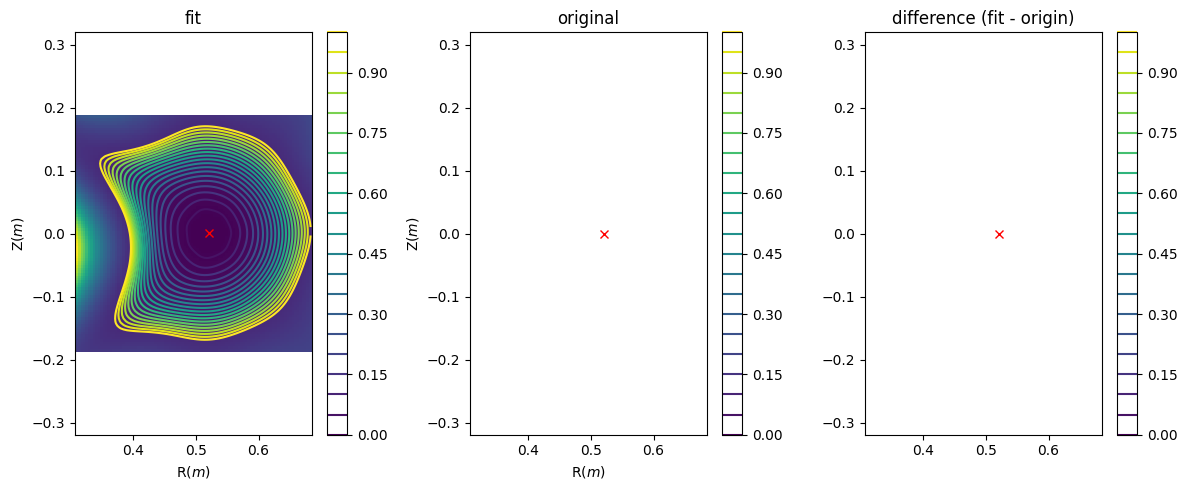

In [51]:
# Plot the numerical result, the original Psi and the difference
# In NORMALIZED UNITS
fig, axes = plt.subplots(nrows=1, ncols=3, sharex=True, figsize=(12, 5), squeeze=False)

ax = axes[0][0]
levels = np.linspace( 0, 1, 21,endpoint=True)
cf = ax.pcolormesh(r3d[:,:,phi_idx]+raxis[phi_idx],z3d[:,:,phi_idx]+zaxis[phi_idx],s3d[:,:,phi_idx])


cf = ax.contour(r3d[:,:,phi_idx]+raxis[phi_idx], z3d[:,:,phi_idx]+zaxis[phi_idx], s3d[:,:,phi_idx], levels)
fig.colorbar(cf, ax=ax)
# ax.clabel(cf)
# cf = ax.scatter(r, z, c=psip_fit)
ax.plot( raxis[phi_idx], zaxis[phi_idx], 'rx')

ax.axis("equal")
ax.set_title("fit")
ax.set_xlabel(r'R($m$)')
ax.set_ylabel(r'Z($m$)')
ax = axes[0][1]
# cf = ax.scatter( R_ijk[:,:,phi_idx],Z_ijk[:,:,phi_idx],c=s_ijk[1:,:,phi_idx])
ax.plot( raxis[phi_idx], zaxis[phi_idx], 'rx')
fig.colorbar(cf, ax=ax)
ax.axis("equal")
ax.set_xlabel(r"R($m$)")
ax.set_ylabel(r"Z($m$)")
ax.set_title(r"$s$")

ax.set_title("original")
ax = axes[0][2]
# cf = ax.scatter(R_ijk[:,:,phi_idx], Z_ijk[:,:,phi_idx], c=(psip_fit - np.sqrt(s_ijk))[:,:,phi_idx], 
#                 cmap = 'seismic', vmin = -1e-2, vmax = 1e-2)
ax.plot( raxis[phi_idx], zaxis[phi_idx], 'rx')
ax.axis("equal")
ax.set_title("difference (fit - origin)")
fig.colorbar(cf, ax=ax)


fig.tight_layout()

plt.show()


Fitting $\sqrt{s}$ seems to improve fit for s outside the fitting region (no oscillations)


(0.0, 1.0)

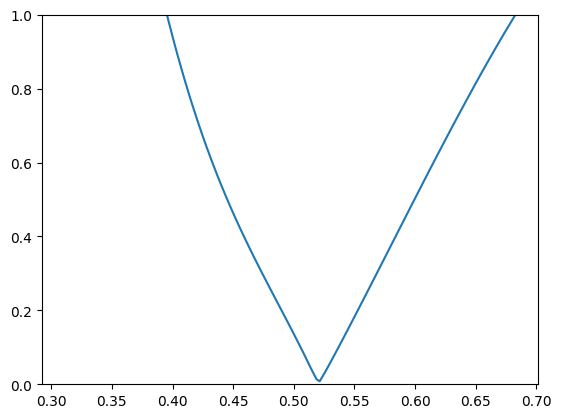

In [52]:
zidx = int(3*32/2)
plt.plot( r3d[:,zidx, phi_idx]+raxis[phi_idx], np.sqrt(s3d[:,zidx,phi_idx]))
ax = plt.gca()
ax.set_ylim([0,1])


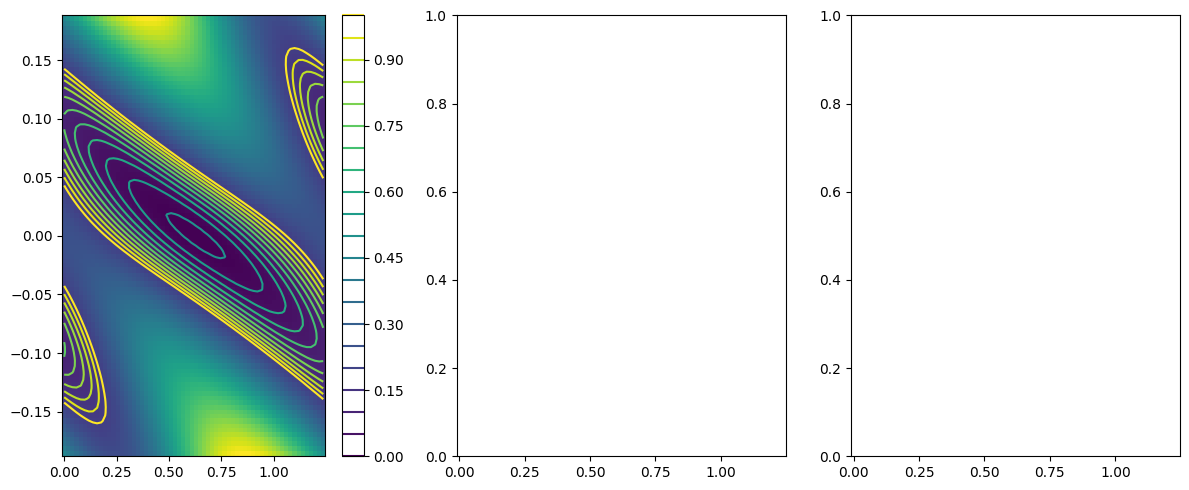

In [53]:
fig, axes = plt.subplots(nrows=1, ncols=3, sharex=True, figsize=(12, 5), squeeze=False)

##################################################################
ax = axes[0][0]
levels = np.linspace( 0, 1, 21,endpoint=True)
R_idx = 20
cf = ax.pcolormesh(p3d[R_idx,:,:],z3d[R_idx,:,:]+zaxis[phi_idx],s3d[R_idx,:,:])
cf = ax.contour(p3d[R_idx,:,:], z3d[R_idx,:,:]+zaxis[phi_idx], s3d[R_idx,:,:], levels)
fig.colorbar(cf, ax=ax)
# ax.clabel(cf)
# cf = ax.scatter(r, z, c=psip_fit)
# ax.plot( raxis_k[phi_idx], zaxis_k[phi_idx], 'rx')

# ax.axis("equal")
# ax.set_title("fit")
# ax.set_xlabel(r"$\varphi$")
# ax.set_ylabel(r'Z($m$)')
# ax = axes[0][1]
# ax.scatter( p_ijk[:,:,:],Z_ijk[:,:,:],c=s_ijk[:,:,:])
# ax.axis("equal")
# ax.set_xlabel(r"$\varphi$")
# ax.set_ylabel(r"Z($m$)")
# ax.set_title(r"$s$")

# ax.set_title("original")
# ax = axes[0][2]
# cf = ax.scatter(p_ijk[:,:,:], Z_ijk[:,:,:], c=(psip_fit - s_ijk)[:,:,:], 
#                 cmap = 'seismic', vmin = -1e-2, vmax = 1e-2)
# ax.axis("equal")
# ax.set_title("difference (fit - origin)")
# fig.colorbar(cf, ax=ax)


fig.tight_layout()

plt.show()

## Fit in Lambda

angle  2.454369260617026


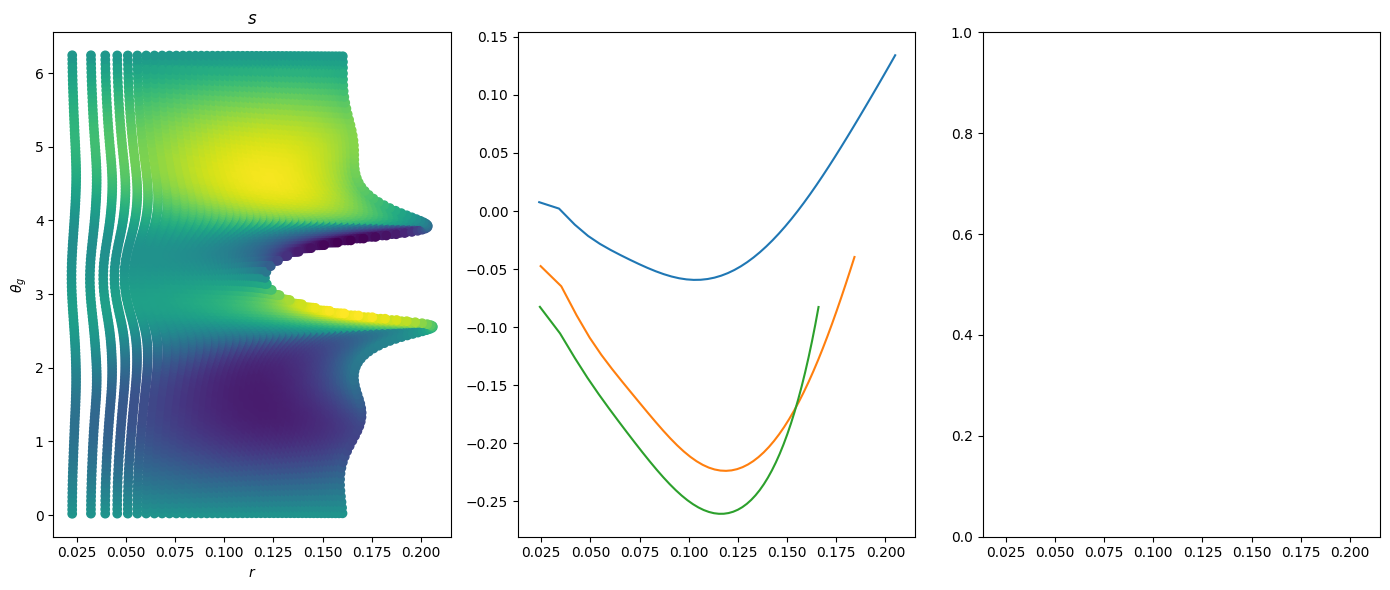

In [54]:
# Plot lambda in r, theta, phi coordinates
fig, axes = plt.subplots(nrows=1, ncols=3, sharex=True, figsize=(14, 6), squeeze=False)

ax = axes[0][0]
ax.scatter( radius_ijk[:,:,4],theta_gijk[:,:,4],c=tilde_lambda_ijk[:,:,4])
# ax.plot( raxis, zaxis, 'rx')
# ax.axis("equal")
ax.set_xlabel(r"$r$")
ax.set_ylabel(r"$\theta_g$")
ax.set_title(r"$s$")
ax = axes[0][1]
rs = np.linspace(0.01, 0.2, 30)
ss = 40*rs**2
ax.plot( radius_ijk[:,52,4], tilde_lambda_ijk[:,52,4])
ax.plot( radius_ijk[:,40,4], tilde_lambda_ijk[:,40,4])
ax.plot( radius_ijk[:,30,4], tilde_lambda_ijk[:,30,4])
# ax.plot( rs, np.sqrt(ss), 'r-')
# ax.axis("equal")
# ax.set_xlim([0.01,0.2])
# ax.set_xscale("log")
# ax.set_yscale("log")
print( "angle ", grid_theta[50])
# # cf = ax.contour(r, z, (theta_rz),300)
# # cf = ax.scatter(r, z, c=(theta_rz+lambda_rz))
# cf = ax.scatter(r, z, c=np.where( theta_rz- theta_g < -np.pi ,theta_rz- theta_g+2*np.pi,
#                                   np.where( theta_rz - theta_g > np.pi, theta_rz- theta_g -2*np.pi,
#                                             theta_rz - theta_g )))#,
#                 # vmin = -0.3, vmax=0.3, cmap = "seismic")
# # cf = ax.scatter(r, z, c=((theta_rz+lambda_rz-theta_g)%(2*np.pi)))
# fig.colorbar(cf, ax=ax)
# ax.plot( raxis, zaxis, 'rx')
# ax.axis("equal")
# ax.set_xlabel(r"R($m$)")
# ax.set_ylabel(r"Z($m$)")
# ax.set_title(r"$\tilde \theta$")
# ax = axes[0][2]
# cf = ax.scatter(r, z, c= lambda_rz, vmin = -0.3, vmax=0.3, cmap = "seismic")
# ax.plot( raxis, zaxis, 'rx')
# ax.axis("equal")
# fig.colorbar(cf, ax=ax)
# ax.set_title(r"$\lambda$")
fig.tight_layout()

plt.show()

In [55]:
# from scipy.special import laguerre # Makes the same fit
degr = 3
mpol = 8 # wout nice has 8, w7x has 12
ntor = 6 # wout nice has 6, w7x has 12
xm_l = []
xn_l = []

for i in range(mpol):
    for j in range(-ntor, ntor+1):
        if i == 0 and j < 0:
            continue
        else:
            xm_l.append(i)
            xn_l.append(j*wout.nfp)
modesK = len(xm_l)
xmm = np.array(xm_l)
xnn = np.array(xn_l)
c = np.array(np.zeros(degr * modesK ))

def lambda_fit(x, *c):
    """ The function to fit to the data """
    r, theta, phi = x
    
    jac2d = np.sin( np.outer(  theta, xmm) - np.outer(phi,xnn)) ## jac2d is 2d, xm is 2nd dimension, theta 1st
    result = 0
    for i in range(degr):
        result += r**(i)* (jac2d @ c[i*modesK:(i+1)*modesK])
        # result += laguerre(i)(r/0.2)* (jac2d @ c[i*modesK:(i+1)*modesK])
        
    
    return result

def lambda_jac_fit(x, *c):
    """ Its Jacobian """
    r, theta, phi = x
    jac = np.zeros( (len(r), degr*modesK))
    for i in range(degr):
        for j in range(modesK):
            jac[:, i*modesK+j] = r**i* np.sin( xmm[j]*theta - xnn[j]*phi)
            # jac[:, i*modesK+j] = laguerre(i)(r/0.2)* np.sin( xmm[j]*theta - xnn[j]*phi)
    
    return jac
def tilde_lambda_fct(R,Z,P):
    """ The function to fit to the data """
    rad = np.sqrt( R**2+Z**2)
    if rad == 0:
        rad = 1e-16
    if Z > 0:
        the = np.arccos ( R/rad)
    else:
        the = 2*np.pi-np.arccos (R/rad)
    
    jj = np.sin( the* xmm - P*xnn) ## jac2d is 2d, xm is 2nd dimension, theta 1st
    result = 0
    for i in range(degr):
        result += rad**(i)* np.dot(jj, copt[i*modesK:(i+1)*modesK])
        # result += laguerre(i)(rad/0.2)* np.dot(jj, copt[i*modesK:(i+1)*modesK])
    
    return result

In [56]:
# We need to ravel the meshgrids of X, Y points
# to a pair of 1-D arrays:
# coords = np.vstack((radius_ijk.ravel(),theta_gijk.ravel(), p_ijk.ravel()))
coords = np.vstack((radius_ijk.ravel(),theta_gijk.ravel(), p_ijk.ravel()))
tilde_lambda_exp = tilde_lambda_ijk.ravel()

In [57]:
# Solve linear least squares
A = lambda_jac_fit( coords, *c)
clstsq,res,rank,singular = np.linalg.lstsq( A, tilde_lambda_exp)
print("Shape of jacobian", A.shape)

Shape of jacobian (393216, 294)


In [59]:
copt = clstsq
tilde_lambda_fit = lambda_fit(coords, *copt)
tilde_lambda_fit = (tilde_lambda_fit).reshape(radius_ijk.shape)
difference = tilde_lambda_fit - tilde_lambda_ijk
print( difference.shape)
print(
    "Relative Error in Psi is      ",
    np.linalg.norm(difference.ravel(), ord=2) / np.linalg.norm(tilde_lambda_ijk.ravel(), ord=2),
)

(48, 128, 64)
Relative Error in Psi is       0.08688387651207136


In [60]:
tilde_lambda3d = dg.evaluate( tilde_lambda_fct, g3d).reshape(g3d.shape)

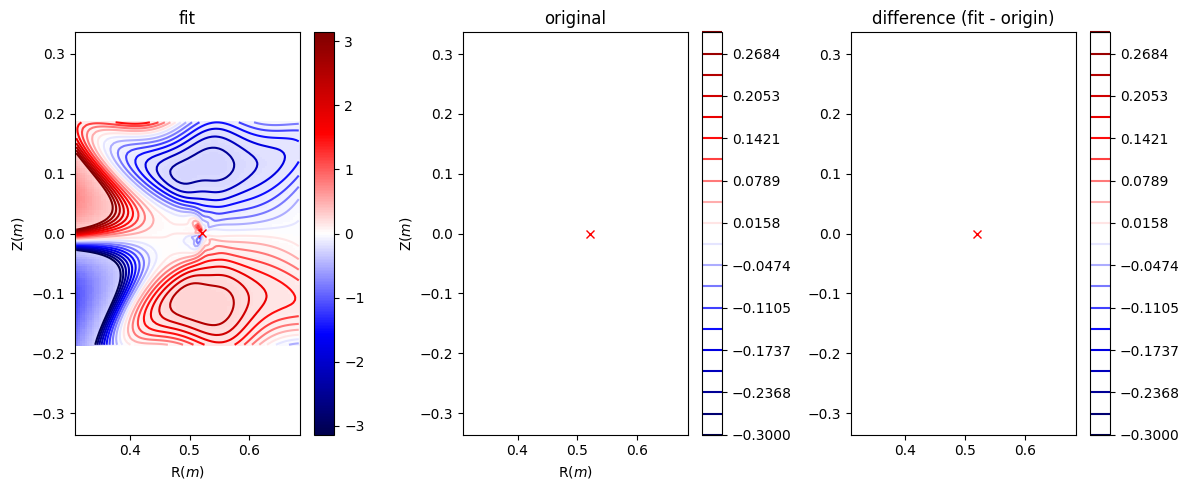

In [62]:
# Plot the numerical result, the original Psi and the difference
# In NORMALIZED UNITS
fig, axes = plt.subplots(nrows=1, ncols=3, sharex=True, figsize=(12, 5), squeeze=False)

ax = axes[0][0]
levels = np.linspace(-0.3, 0.3, 20,endpoint=True)
cf = ax.pcolormesh(r3d[:,:,phi_idx]+raxis[phi_idx],z3d[:,:,phi_idx]+zaxis[phi_idx],tilde_lambda3d[:,:,phi_idx],
                   vmin = -np.pi, vmax=np.pi, cmap = "seismic")
fig.colorbar(cf, ax=ax)

cf = ax.contour(r3d[:,:,phi_idx]+raxis[phi_idx], z3d[:,:,phi_idx]+zaxis[phi_idx],
                tilde_lambda3d[:,:,phi_idx], levels, cmap = 'seismic')

# ax.clabel(cf)
# cf = ax.scatter(r, z, c=psip_fit)
ax.plot( raxis[phi_idx], zaxis[phi_idx], 'rx')

ax.axis("equal")
ax.set_title("fit")
ax.set_xlabel(r'R($m$)')
ax.set_ylabel(r'Z($m$)')
ax = axes[0][1]
# cf = ax.scatter( R_ijk[:,:,phi_idx],Z_ijk[:,:,phi_idx],c=tilde_lambda_ijk[:,:,phi_idx],
#           vmin = -0.3, vmax=0.3, cmap = "seismic")
fig.colorbar(cf, ax=ax)
ax.plot( raxis[phi_idx], zaxis[phi_idx], 'rx')
ax.axis("equal")
ax.set_xlabel(r"R($m$)")
ax.set_ylabel(r"Z($m$)")
ax.set_title("original")
ax = axes[0][2]
# cf = ax.scatter(R_ijk[:,:,phi_idx], Z_ijk[:,:,phi_idx], c=(tilde_lambda_fit - tilde_lambda_ijk)[:,:,phi_idx],
#                 cmap = 'seismic', vmin = -1e-2, vmax = 1e-2)
ax.plot( raxis[phi_idx], zaxis[phi_idx], 'rx')
ax.axis("equal")
ax.set_title("difference (fit - origin)")
fig.colorbar(cf, ax=ax)
fig.tight_layout()

plt.show()

In [ ]:
S = 2**25 
Tnvshmem = 2e5 
TMPId = 3e2
TMPIh = 2e3
Tnccl = 2e2

Bnvshmem = S /1e9 / Tnvshmem * 1e6
BMPId = S /1e9 / TMPId * 1e6
BMPIh = S /1e9 / TMPIh * 1e6
Bnccl = S /1e9 / Tnccl * 1e6
print( Bnvshmem, BMPId, BMPIh, Bnccl)

## Polynomial fit in 2d

In [ ]:
# # The degree of the polynomial determines how long the fitting
# # takes but also how good the fit will be
# # decrease if possible, increase if necessary
# degR = 8
# degZ = 8
# params = dg.geo.polynomial.Parameters()
# params.R_0 = 1
# params.pp = 1
# params.M = degR  # degree in R
# params.N = degZ  # degree in Z

# c = np.array(np.zeros(degR * degZ ))

# def psi_fit(x, *c):
#     """ The function to fit to the data """
#     R, Z = x

#     params.c = list(c)

#     psip = dg.geo.polynomial.Psip(params)
#     return psip(R, Z)

# c = np.array(np.zeros(degR * degZ - 3 ))

# def psi_fit3(x, *c):
#     """ The function to fit to the data """
#     R, Z = x

#     tmp = list(c)
#     tmp.insert(0,0)
#     tmp.insert(0,0)
#     tmp.insert(degZ, 0)
#     params.c = tmp
#     # print( params.c)

#     psip = dg.geo.polynomial.Psip(params)
#     return psip(R, Z)
    
# def jac_fit(x, *c):
#     """ Its Jacobian """
#     R, Z = x
#     jac = np.zeros(( len(R), len(c)))
#     for i in range(0,degR):
#         for j in range(0,degZ):
#             jac[:,i*degZ+j] = R**i*Z**j 
    
#     return jac

In [ ]:
# # With this function we can experiment to weigh the fitting 
# # It usually works better without

# def sigma ( psi): 
#     if psi > 1:
#         return 100 #basically removes these points from fit
#     else:
#         return 1

In [ ]:
# We need to ravel the meshgrids of X, Y points
# # to a pair of 1-D arrays:
# coords = np.vstack(((ext_r-raxis).ravel(),(ext_z-zaxis).ravel()))
# psip_exp = ext_s_rz.ravel()
# # in case we have a sigma
# weights = np.array([sigma(psi) for psi in psip_exp])

In [ ]:
# import time
# from scipy.optimize import curve_fit
# start = time.monotonic()
# # Here comes the fit (might take a while)
# # Providing the Jacobian accelerates the fit but the result is terrible
# # copt, pcov = curve_fit(psi_fit, coords, psip_exp, c, weights, jac = jac_fit)
# # copt, pcov = curve_fit(psi_fit, coords, psip_exp, c, weights)
# copt, pcov = curve_fit(psi_fit3, coords, psip_exp, c, weights)
# copt = np.insert(copt, 0,0)
# copt = np.insert(copt, 0,0)
# copt = np.insert(copt, degZ, 0)
# stop = time.monotonic()
# print("Took / s", stop - start)
# print(copt)

In [ ]:
# # Solve linear least squares
# A = jac_fit( coords, *c)
# B = np.transpose(A)@A
# print(psip_exp.shape)
# # print( "Eigenvalues", np.linalg.eig(B))
# print("Condition number ", np.linalg.cond(B))

# clstsq,res,rank,singular = np.linalg.lstsq( A, psip_exp)
# print(singular)
# clstsq

In [ ]:
# coords = np.vstack(((r-raxis).ravel(),(z-zaxis).ravel()))
# psip_fit = psi_fit(coords, *copt)
# psip_fit = psip_fit.reshape(r.shape)
# difference = psip_fit - s_rz
# print(
#     "Relative Error in Psi is      ",
#     np.linalg.norm(difference, ord=2) / np.linalg.norm(s_rz.ravel(), ord=2),
# )

In [ ]:
# g2d = dg.Grid([ r.min()-raxis, z.min()-zaxis], [ r.max()-raxis, z.max()-zaxis],
#               [3,3], [80, 80])
# r2d = dg.evaluate( lambda x,y: x, g2d).reshape(g2d.shape)
# z2d = dg.evaluate( lambda x,y: y, g2d).reshape(g2d.shape)
# params.c = list(copt)
# psip = dg.geo.polynomial.Psip(params)
# print( psip(0.1, 0.1))
# s2d = dg.evaluate( psip, g2d).reshape(g2d.shape)

In [ ]:
# # Plot the numerical result, the original Psi and the difference
# # In NORMALIZED UNITS
# fig, axes = plt.subplots(nrows=1, ncols=3, sharex=True, figsize=(12, 5), squeeze=False)

# ax = axes[0][0]
# levels = np.linspace( 0, 2, 20)
# # ax.pcolormesh(r2d+raxis,z2d+zaxis,s2d)
# cf = ax.contour(r2d+raxis,z2d+zaxis, s2d, levels)
# # ax.clabel(cf)
# # cf = ax.scatter(r, z, c=psip_fit)
# ax.plot( raxis, zaxis, 'rx')
# ax.axis("equal")
# ax.set_title("fit")
# ax.set_xlabel(r'R($m$)')
# ax.set_ylabel(r'Z($m$)')
# ax = axes[0][1]
# ax.scatter( r,z,c=s_rz)
# ax.plot( raxis, zaxis, 'rx')
# ax.axis("equal")
# ax.set_xlabel(r"R($m$)")
# ax.set_ylabel(r"Z($m$)")
# ax.set_title(r"$s$")

# ax.set_title("original")
# ax = axes[0][2]
# cf = ax.scatter(r, z, c=(psip_fit - s_rz), cmap = 'seismic', vmin = -1e-2, vmax = 1e-2)
# ax.plot( raxis, zaxis, 'rx')
# ax.axis("equal")
# ax.set_title("difference (fit - origin)")
# fig.colorbar(cf, ax=ax)
# fig.tight_layout()

# plt.show()